<a href="https://colab.research.google.com/github/DOHA-BASEM3/DS330-Deep-Learning-Project/blob/main/CCPP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Dataset Description

**Dataset Name:** Combined Cycle Power Plant (CCPP)

**Source:** UCI Machine Learning Repository.

**Dataset Link:** https://archive.ics.uci.edu/dataset/294/combined+cycle+power+plant

**Dataset Type:** Tabular Data – Supervised Learning – Regression.

**Features:**
- AT: Ambient Temperature.
- V: Exhaust Vacuum.
- AP: Ambient Pressure.
- RH: Relative Humidity.

**Target Variable:**
- PE: Net Hourly Electrical Energy Output.

**Problem Definition:**
The objective is to train a deep neural network to predict the net hourly electrical energy output (PE) using four environmental and operational input features.

**Why PE was selected as the target:**
PE is a continuous numerical variable, making it suitable for a regression problem.

# **Dataset Loading**

In [281]:
%pip install -q ucimlrepo

In [282]:

# Import libraries
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import time
import matplotlib.pyplot as plt

from torch.utils.data import TensorDataset, DataLoader
from ucimlrepo import fetch_ucirepo

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Check device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Load Combined Cycle Power Plant dataset
power_plant = fetch_ucirepo(id=294)

# Separate input features and target variable
X = power_plant.data.features.copy()
y = power_plant.data.targets.copy()

# Combine features and target for initial inspection
df = pd.concat([X, y], axis=1)

# Display dataset information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget variable:")
print(y.columns.tolist())

# Display first five rows
display(df.head())


Using device: cpu
Dataset loaded successfully!
Dataset shape: (9568, 5)

Input features:
['AT', 'V', 'AP', 'RH']

Target variable:
['PE']


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


Data Quality Assessment and Descriptive Statistics

In [283]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nStatistical summary:")
display(df.describe())


Missing values:
AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

Duplicate rows:
41

Data types:
AT    float64
V     float64
AP    float64
RH    float64
PE    float64
dtype: object

Statistical summary:


,AT,V,AP,RH,PE
count,9568.000000,9568.000000,9568.000000,9568.000000,9568.000000
mean,19.651231,54.305804,1013.259078,73.308978,454.365009
std,7.452473,12.707893,5.938784,14.600269,17.066995
min,1.810000,25.360000,992.890000,25.560000,420.260000
25%,13.510000,41.740000,1009.100000,63.327500,439.750000
50%,20.345000,52.080000,1012.940000,74.975000,451.550000
75%,25.720000,66.540000,1017.260000,84.830000,468.430000
max,37.110000,81.560000,1033.300000,100.160000,495.760000


#Data Preprocessing

In [284]:
df = df.drop_duplicates().reset_index(drop=True)

X = df[['AT', 'V', 'AP', 'RH']].copy()
y = df[['PE']].copy()

print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

Dataset shape after removing duplicates: (9527, 5)
Remaining duplicate rows: 0


# **Train / Validation / Test Split**

In [285]:

from sklearn.model_selection import train_test_split

# Split the dataset into training and temporary sets
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

# Split the temporary set into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

# Display dataset split shapes
print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)


Training set: (6668, 4) (6668, 1)
Validation set: (1429, 4) (1429, 1)
Test set: (1430, 4) (1430, 1)


# **Feature Standardization**

In [286]:

from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Fit on training data and transform all sets
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Display the shapes
print("Training set:", X_train_scaled.shape)
print("Validation set:", X_val_scaled.shape)
print("Test set:", X_test_scaled.shape)


print("Training mean:", X_train_scaled.mean(axis=0))
print("Training std:", X_train_scaled.std(axis=0))


Training set: (6668, 4)
Validation set: (1429, 4)
Test set: (1430, 4)
Training mean: [-3.18081894e-16  1.49983338e-16 -1.50995659e-15 -2.05660990e-16]
Training std: [1. 1. 1. 1.]


In [287]:

# Convert training and validation data to PyTorch tensors

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.float32)

X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val.to_numpy(), dtype=torch.float32)

# Create datasets
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Training tensors:", X_train_tensor.shape, y_train_tensor.shape)
print("Validation tensors:", X_val_tensor.shape, y_val_tensor.shape)


Training dataset: 6668
Validation dataset: 1429
Training tensors: torch.Size([6668, 4]) torch.Size([6668, 1])
Validation tensors: torch.Size([1429, 4]) torch.Size([1429, 1])


# **Linear Regression Baseline**

In [288]:

import time
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Create Linear Regression model
linear_model = LinearRegression()

# Measure training time
start_time = time.perf_counter()

# Train the model
linear_model.fit(X_train_scaled, y_train)

linear_training_time = time.perf_counter() - start_time

# Make predictions
y_train_pred = linear_model.predict(X_train_scaled)
y_val_pred = linear_model.predict(X_val_scaled)

# Calculate Mean Squared Error عدلت هووون
linear_train_mse = mean_squared_error(y_train, y_train_pred)
linear_val_mse = mean_squared_error(y_val, y_val_pred)

# Display results
print("Linear Regression Results : ")
print(f"Training MSE: {linear_train_mse:.4f}")
print(f"Validation MSE: {linear_val_mse:.4f}")
print(f"Training Time: {linear_training_time:.4f} seconds")


Linear Regression Results : 
Training MSE: 20.2748
Validation MSE: 21.4396
Training Time: 0.0072 seconds


# **Baseline Deep Neural Network**

Baseline Deep Neural Network Results
Training MSE: 16.7957
Validation MSE: 18.6084
Training Time: 45.82 seconds

Linear Regression Comparison
Linear Regression Validation MSE: 21.4396
Deep Neural Network Validation MSE: 18.6084
Improvement: 13.21%


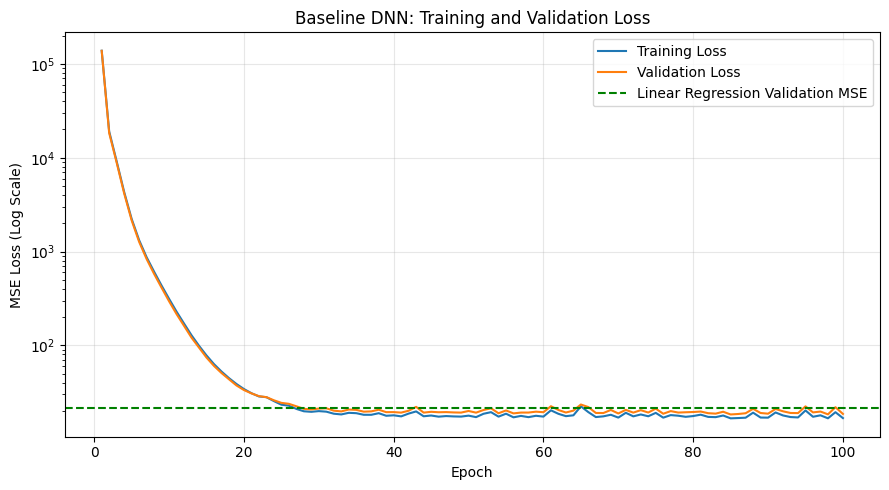

In [289]:

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import time

from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cpu")

# Prepare tensors
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)

y_train_tensor = torch.tensor(
    y_train.to_numpy(), dtype=torch.float32
)
y_val_tensor = torch.tensor(
    y_val.to_numpy(), dtype=torch.float32
)

# Baseline hyperparameters
hidden_layers = [64, 32]
learning_rate = 0.001
batch_size = 32
epochs = 100

# Training data loader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

generator = torch.Generator().manual_seed(42)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    generator=generator
)

# Deep neural network
model = nn.Sequential(
    nn.Linear(4, hidden_layers[0]),
    nn.ReLU(),
    nn.Linear(hidden_layers[0], hidden_layers[1]),
    nn.ReLU(),
    nn.Linear(hidden_layers[1], 1)
).to(device)

# Loss function and optimizer
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate
)

# Training
train_losses = []
val_losses = []

start_time = time.perf_counter()

for epoch in range(epochs):
    model.train()

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        predictions = model(X_batch)
        loss = criterion(predictions, y_batch)
        loss.backward()
        optimizer.step()

    model.eval()

    with torch.no_grad():
        train_predictions = model(X_train_tensor.to(device))
        val_predictions = model(X_val_tensor.to(device))

        train_loss = criterion(
            train_predictions, y_train_tensor.to(device)
        ).item()

        val_loss = criterion(
            val_predictions, y_val_tensor.to(device)
        ).item()

    train_losses.append(train_loss)
    val_losses.append(val_loss)

training_time = time.perf_counter() - start_time

# Baseline results
nn_train_mse = train_losses[-1]
nn_val_mse = val_losses[-1]

print("Baseline Deep Neural Network Results")
print(f"Training MSE: {nn_train_mse:.4f}")
print(f"Validation MSE: {nn_val_mse:.4f}")
print(f"Training Time: {training_time:.2f} seconds")

print("\nLinear Regression Comparison")
print(f"Linear Regression Validation MSE: {linear_val_mse:.4f}")
print(f"Deep Neural Network Validation MSE: {nn_val_mse:.4f}")

improvement = (
    (linear_val_mse - nn_val_mse)
    / linear_val_mse
) * 100
print(f"Improvement: {improvement:.2f}%")

# Loss curves
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, epochs + 1),
    train_losses,
    label="Training Loss"
)

plt.plot(
    range(1, epochs + 1),
    val_losses,
    label="Validation Loss"
)

plt.axhline(
    y=linear_val_mse,
    color="green",
    linestyle="--",
    label="Linear Regression Validation MSE"
)

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss (Log Scale)")
plt.title("Baseline DNN: Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [290]:
# Create comparison table automatically

comparison_df = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Deep Neural Network"
    ],

    "Training MSE": [
        linear_train_mse,
        nn_train_mse
    ],

    "Validation MSE": [
        linear_val_mse,
        nn_val_mse
    ],

    "Training Time (s)": [
        linear_training_time,
        training_time
    ]
})

display(comparison_df.round(4))

,Model,Training MSE,Validation MSE,Training Time (s)
0,Linear Regression,20.2748,21.4396,0.0072
1,Deep Neural Network,16.7957,18.6084,45.8170


## Baseline Results Comparison
**Observation**

The Deep Neural Network achieved a lower validation MSE than Linear Regression (18.6084 vs. 21.4396), reducing the validation error by approximately 13.21%.

However, Linear Regression required much less training time. This shows a trade-off between predictive performance and computational cost.

The results will serve as a baseline for evaluating the upcoming hyperparameter experiments.

# **Hyperparameter Experiments**

## <font color="#3B82F6">Learning Rate</font>



### Learning Rate Experiment 1 — LR = 0.0001

In [291]:

def run_learning_rate_experiment(lr):
    torch.manual_seed(42)
    np.random.seed(42)

    generator = torch.Generator().manual_seed(42)

    loader = DataLoader(
        train_dataset,
        batch_size=32,
        shuffle=True,
        generator=generator
    )
 # Create a new model
    experiment_model = nn.Sequential(
        nn.Linear(4, 64),
        nn.ReLU(),
        nn.Linear(64, 32),
        nn.ReLU(),
        nn.Linear(32, 1)
    ).to(device)

    loss_fn = nn.MSELoss()
    experiment_optimizer = torch.optim.Adam(
        experiment_model.parameters(), lr=lr
    )

    training_losses = []
    validation_losses = []

    start_time = time.perf_counter()

    for epoch in range(100):
        experiment_model.train()

        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            experiment_optimizer.zero_grad()
            loss = loss_fn(experiment_model(xb), yb)
            loss.backward()
            experiment_optimizer.step()

        experiment_model.eval()

        with torch.no_grad():
            train_mse_epoch = loss_fn(
                experiment_model(X_train_tensor.to(device)),
                y_train_tensor.to(device)
            ).item()

            val_mse_epoch = loss_fn(
                experiment_model(X_val_tensor.to(device)),
                y_val_tensor.to(device)
            ).item()

        training_losses.append(train_mse_epoch)
        validation_losses.append(val_mse_epoch)

    elapsed = time.perf_counter() - start_time

    return {
        "Learning Rate": lr,
        "Train MSE": training_losses[-1],
        "Val MSE": validation_losses[-1],
        "Time (s)": elapsed,
        "Train Losses": training_losses,
        "Val Losses": validation_losses
    }


lr_results = []

result = run_learning_rate_experiment(0.0001)
lr_results.append(result)

print("Learning Rate:", result["Learning Rate"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")


Learning Rate: 0.0001
Training MSE: 31.7889
Validation MSE: 31.3234
Training Time: 28.31 seconds


### Learning Rate Experiment 2 — LR = 0.0003

In [292]:

result = run_learning_rate_experiment(0.0003)
lr_results.append(result)

print("Learning Rate:", result["Learning Rate"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")


Learning Rate: 0.0003
Training MSE: 17.4802
Validation MSE: 19.0203
Training Time: 30.17 seconds


### Learning Rate Experiment 3 — LR = 0.003

In [293]:

result = run_learning_rate_experiment(0.003)
lr_results.append(result)

print("Learning Rate:", result["Learning Rate"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")


Learning Rate: 0.003
Training MSE: 17.2582
Validation MSE: 19.1169
Training Time: 28.55 seconds


### Learning Rate Experiment 4 — LR = 0.01

In [294]:

result = run_learning_rate_experiment(0.01)
lr_results.append(result)

print("Learning Rate:", result["Learning Rate"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")


Learning Rate: 0.01
Training MSE: 21.0044
Validation MSE: 23.7329
Training Time: 28.08 seconds


### Learning Rate Experiment 5 — LR = 0.03

In [295]:

result = run_learning_rate_experiment(0.03)
lr_results.append(result)

print("Learning Rate:", result["Learning Rate"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")


Learning Rate: 0.03
Training MSE: 31.6638
Validation MSE: 35.6667
Training Time: 28.51 seconds


### Learning Rate Experiment 5 — LR = 0.0005

In [296]:

result = run_learning_rate_experiment(0.0005)
lr_results.append(result)

print("Learning Rate:", result["Learning Rate"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")

Learning Rate: 0.0005
Training MSE: 17.5269
Validation MSE: 19.1729
Training Time: 28.41 seconds


### Learning Rate Experiment 5 — LR = 0.002

In [297]:
result = run_learning_rate_experiment(0.002)
lr_results.append(result)

print("Learning Rate:", result["Learning Rate"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")

Learning Rate: 0.002
Training MSE: 16.5886
Validation MSE: 18.2036
Training Time: 28.39 seconds


### Learning Rate Experiments — Results Summary

In [298]:

lr_table = pd.DataFrame([
    {
        "Run": "Baseline",
        "Learning Rate": 0.001,
        "Train MSE": nn_train_mse,
        "Val MSE": nn_val_mse,
        "Time (s)": training_time
    },
    *[
        {
            "Run": f"LR Experiment {i}",
            "Learning Rate": r["Learning Rate"],
            "Train MSE": r["Train MSE"],
            "Val MSE": r["Val MSE"],
            "Time (s)": r["Time (s)"]
        }
        for i, r in enumerate(lr_results, start=1)
    ]
])

display(lr_table.round({
    "Learning Rate": 4,
    "Train MSE": 4,
    "Val MSE": 4,
    "Time (s)": 2
}))


,Run,Learning Rate,Train MSE,Val MSE,Time (s)
0,Baseline,0.0010,16.7957,18.6084,45.82
1,LR Experiment 1,0.0001,31.7889,31.3234,28.31
2,LR Experiment 2,0.0003,17.4802,19.0203,30.17
3,LR Experiment 3,0.0030,17.2582,19.1169,28.55
4,LR Experiment 4,0.0100,21.0044,23.7329,28.08
5,LR Experiment 5,0.0300,31.6638,35.6667,28.51
6,LR Experiment 6,0.0005,17.5269,19.1729,28.41
7,LR Experiment 7,0.0020,16.5886,18.2036,28.39


### Learning Rate — Loss Curves

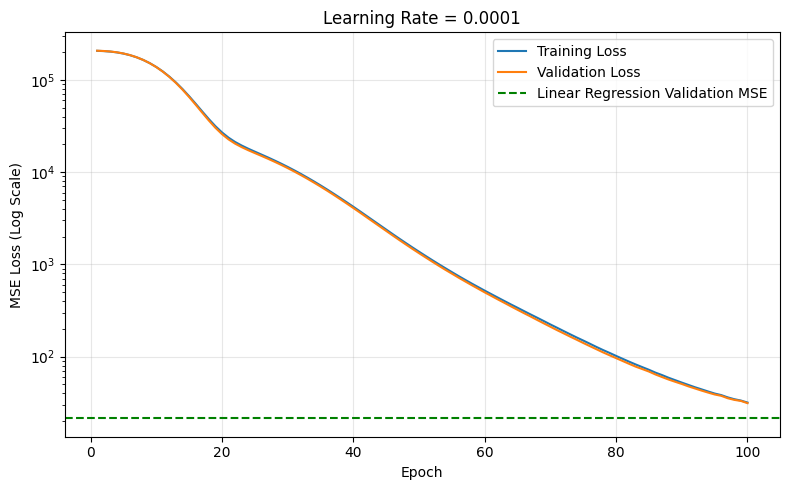

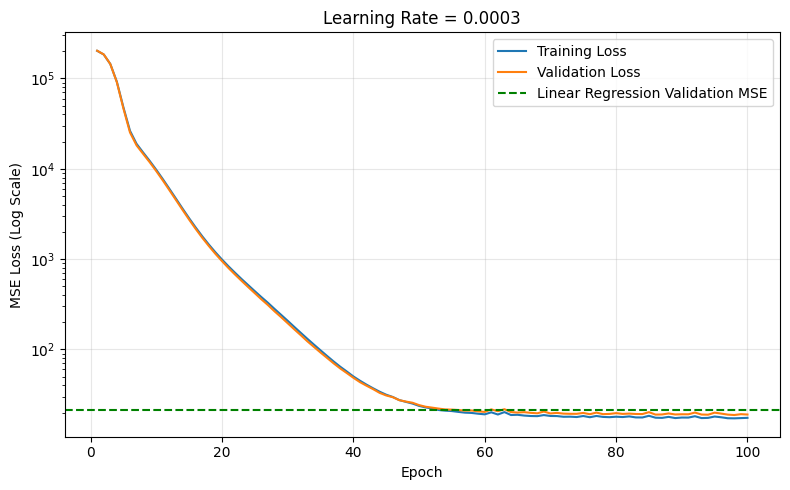

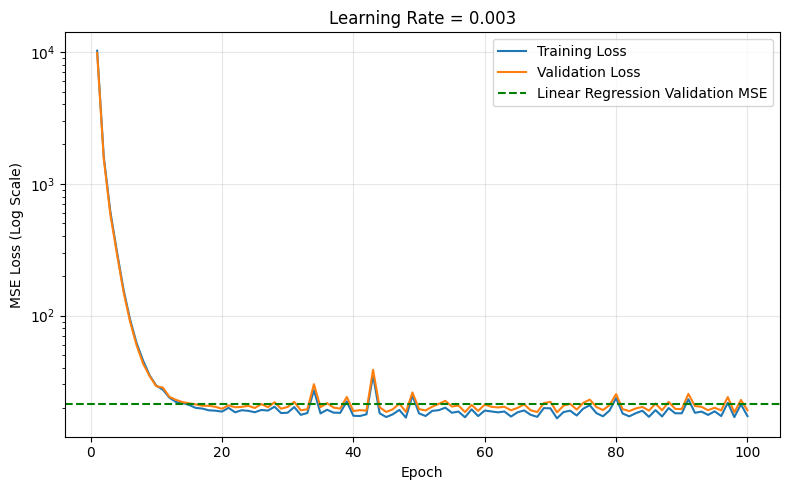

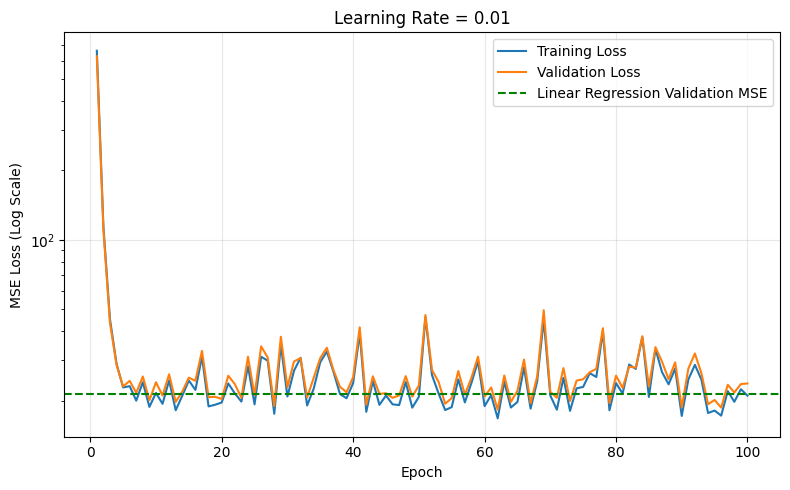

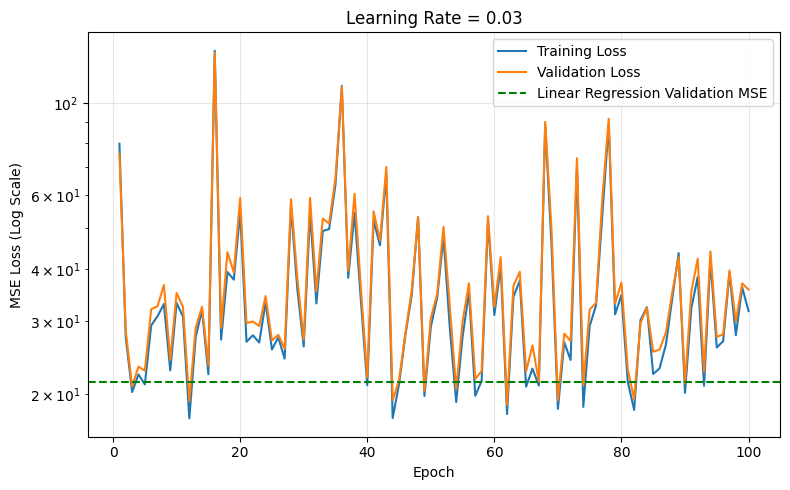

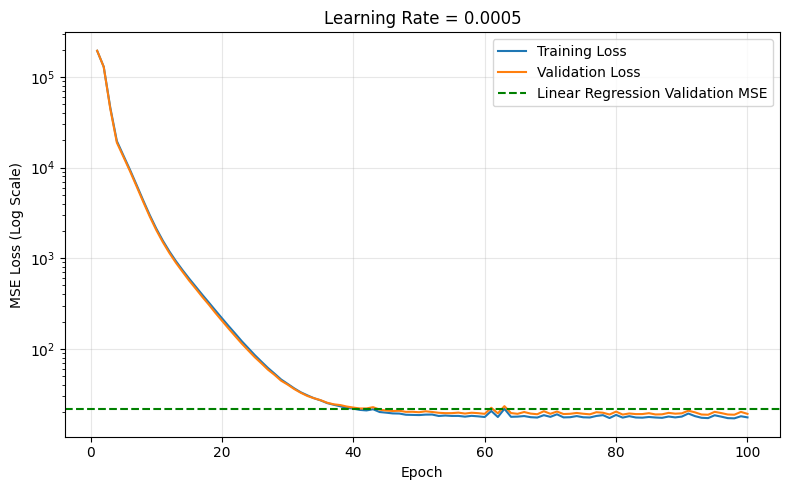

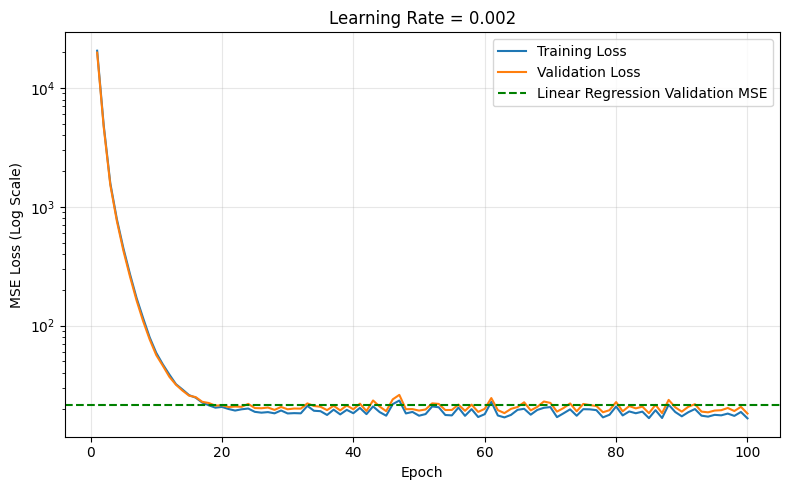

In [299]:

for r in lr_results:
    plt.figure(figsize=(8, 5))

    plt.plot(
        range(1, len(r["Train Losses"]) + 1),
        r["Train Losses"],
        label="Training Loss"
    )

    plt.plot(
        range(1, len(r["Val Losses"]) + 1),
        r["Val Losses"],
        label="Validation Loss"
    )

    plt.axhline(
        y=linear_val_mse,
        color="green",
        linestyle="--",
        label="Linear Regression Validation MSE"
    )

    plt.yscale("log")
    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss (Log Scale)")
    plt.title(f"Learning Rate = {r['Learning Rate']}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


## <font color="#3B82F6">Optimizer </font>

In [306]:
import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

def run_optimizer_experiment(optimizer_name, lr=0.001, momentum=0.9):

    # Reproducibility
    torch.manual_seed(42)
    np.random.seed(42)

    generator = torch.Generator().manual_seed(42)

    # DataLoader
    loader = DataLoader(
        train_dataset,
        batch_size=32,
        shuffle=True,
        generator=generator
    )

    # Same baseline architecture
    model = nn.Sequential(
        nn.Linear(4, 64),
        nn.ReLU(),
        nn.Linear(64, 32),
        nn.ReLU(),
        nn.Linear(32, 1)
    ).to(device)


    # Choose optimizer

    # Choose optimizer
    if optimizer_name == "SGD":
        optimizer = torch.optim.SGD(
            model.parameters(),
            lr=lr,
            momentum=0.0
        )

    elif optimizer_name == "SGD + Momentum":
        optimizer = torch.optim.SGD(
            model.parameters(),
            lr=lr,
            momentum=momentum
        )

    else:
        raise ValueError("Unknown optimizer")

    # Loss function
    criterion = nn.MSELoss()

    train_losses = []
    val_losses = []

    start_time = time.perf_counter()

    # Training
    for epoch in range(100):

        model.train()

        for xb, yb in loader:

            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            predictions = model(xb)
            loss = criterion(predictions, yb)

            loss.backward()
            optimizer.step()

        # Evaluation
        model.eval()

        with torch.no_grad():

            train_mse = criterion(
                model(X_train_tensor.to(device)),
                y_train_tensor.to(device)
            ).item()

            val_mse = criterion(
                model(X_val_tensor.to(device)),
                y_val_tensor.to(device)
            ).item()

        train_losses.append(train_mse)
        val_losses.append(val_mse)

        # Stop if numerical instability occurs
        if not np.isfinite(train_mse) or not np.isfinite(val_mse):
            break

    training_time = time.perf_counter() - start_time

    # Return results
    return {
    "Optimizer": optimizer_name,
    "Learning Rate": lr,
    "Momentum": (
        momentum if optimizer_name == "SGD + Momentum"
        else 0.0 if optimizer_name == "SGD"
        else None
    ),
    "Train MSE": train_mse,
    "Val MSE": val_mse,
    "Time (s)": training_time,
    "Epochs Completed": len(train_losses),
    "Train Losses": train_losses,
    "Val Losses": val_losses
}

###Optimizer Experiment 1 — SGD

In [307]:
# Initialize optimizer results
optimizer_results = []

# Run SGD experiment
result = run_optimizer_experiment("SGD")

# Save result
optimizer_results.append(result)

# Display results
print("Optimizer:", result["Optimizer"])
print("Learning Rate:", result["Learning Rate"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")
print("Epochs Completed:", result["Epochs Completed"])

Optimizer: SGD
Learning Rate: 0.001
Training MSE: nan
Validation MSE: nan
Training Time: 0.77 seconds
Epochs Completed: 1


###Optimizer Experiment 2 — SGD with Momentum (0.9)

In [308]:
# Optimizer Experiment 2 - SGD with Momentum 0.9

result = run_optimizer_experiment("SGD + Momentum")

optimizer_results.append(result)

print("Optimizer:", result["Optimizer"])
print("Learning Rate:", result["Learning Rate"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")
print("Epochs Completed:", result["Epochs Completed"])

Optimizer: SGD + Momentum
Learning Rate: 0.001
Training MSE: nan
Validation MSE: nan
Training Time: 0.42 seconds
Epochs Completed: 1


### Optimizer Experiment 3 — SGD Stability Test (LR = 0.00001)

In [309]:

# Optimizer Experiment 3 - SGD Stability Test

result = run_optimizer_experiment(
    "SGD",
    lr=0.00001
)

# Save result
optimizer_results.append(result)

# Display results
print("Optimizer:", result["Optimizer"])
print(f"Learning Rate: {result['Learning Rate']:.5f}")
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")
print("Epochs Completed:", result["Epochs Completed"])


Optimizer: SGD
Learning Rate: 0.00001
Training MSE: 17.3211
Validation MSE: 18.8810
Training Time: 23.98 seconds
Epochs Completed: 100


###Optimizer Experiment 4 — SGD with Momentum (LR = 0.00001)

In [311]:

# Optimizer Experiment 4 - SGD with Momentum (0.9)

result = run_optimizer_experiment(
    "SGD + Momentum",
    lr=0.00001,
    momentum=0.9
)

# Update Experiment 4 in the results list
optimizer_results.append(result)

# Display results
print("Optimizer:", result["Optimizer"])
print(f"Learning Rate: {result['Learning Rate']:.5f}")
print("Momentum:", result["Momentum"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")
print("Epochs Completed:", result["Epochs Completed"])


Optimizer: SGD + Momentum
Learning Rate: 0.00001
Momentum: 0.9
Training MSE: 16.3380
Validation MSE: 18.0177
Training Time: 24.18 seconds
Epochs Completed: 100


###Optimizer Experiments — Results Summary

In [314]:

# Optimizer Experiments - Results Summary

import pandas as pd
import numpy as np

# Baseline + optimizer experiments
optimizer_table = pd.DataFrame([
    {
        "Run": "Baseline",
        "Optimizer": "Adam",
        "Learning Rate": 0.001,
        "Momentum": None,
        "Train MSE": nn_train_mse,
        "Val MSE": nn_val_mse,
        "Time (s)": None,
        "Epochs": 100
    },

    *[
        {
            "Run": f"Experiment {i}",
            "Optimizer": r["Optimizer"],
            "Learning Rate": r["Learning Rate"],
            "Momentum": r.get("Momentum", None),
            "Train MSE": r["Train MSE"],
            "Val MSE": r["Val MSE"],
            "Time (s)": r["Time (s)"],
            "Epochs": r["Epochs Completed"]
        }
        for i, r in enumerate(optimizer_results, start=1)
    ]
])

# Identify numerical instability
optimizer_table["Status"] = optimizer_table["Val MSE"].apply(
    lambda x: "Valid" if np.isfinite(x) else "NaN"
)

display(optimizer_table.round({
    "Learning Rate": 5,
    "Momentum": 1,
    "Train MSE": 4,
    "Val MSE": 4,
    "Time (s)": 2
}))


,Run,Optimizer,Learning Rate,Momentum,Train MSE,Val MSE,Time (s),Epochs,Status
0,Baseline,Adam,0.00100,NaN,16.7957,18.6084,NaN,100,Valid
1,Experiment 1,SGD,0.00100,0.0,NaN,NaN,0.77,1,NaN
2,Experiment 2,SGD + Momentum,0.00100,0.9,NaN,NaN,0.42,1,NaN
3,Experiment 3,SGD,0.00001,0.0,17.3211,18.8810,23.98,100,Valid
4,Experiment 4,SGD + Momentum,0.00001,0.9,16.3380,18.0177,24.18,100,Valid


## <font color="#3B82F6">Batch Size</font>


In [315]:
import time
import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import DataLoader


def run_batch_size_experiment(batch_size):

    # Reproducibility
    torch.manual_seed(42)
    np.random.seed(42)

    generator = torch.Generator().manual_seed(42)

    # DataLoader
    loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        generator=generator
    )

    # Same baseline model
    model = nn.Sequential(
        nn.Linear(4, 64),
        nn.ReLU(),
        nn.Linear(64, 32),
        nn.ReLU(),
        nn.Linear(32, 1)
    ).to(device)

    # Fixed optimizer
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    # Fixed loss function
    criterion = nn.MSELoss()

    train_losses = []
    val_losses = []

    start_time = time.perf_counter()

    # Training
    for epoch in range(100):

        model.train()

        for xb, yb in loader:

            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            predictions = model(xb)
            loss = criterion(predictions, yb)

            loss.backward()
            optimizer.step()

        # Evaluation
        model.eval()

        with torch.no_grad():

            train_mse = criterion(
                model(X_train_tensor.to(device)),
                y_train_tensor.to(device)
            ).item()

            val_mse = criterion(
                model(X_val_tensor.to(device)),
                y_val_tensor.to(device)
            ).item()

        train_losses.append(train_mse)
        val_losses.append(val_mse)

        # Check numerical stability
        if not np.isfinite(train_mse) or not np.isfinite(val_mse):
            break

    training_time = time.perf_counter() - start_time

    # Return results
    return {
        "Batch Size": batch_size,
        "Train MSE": train_mse,
        "Val MSE": val_mse,
        "Time (s)": training_time,
        "Epochs Completed": len(train_losses),
        "Train Losses": train_losses,
        "Val Losses": val_losses
    }

###Batch Size Experiment 1 — BS = 16

In [317]:
# Batch Size Experiment 1 - BS = 16

batch_results = []

result = run_batch_size_experiment(16)

batch_results.append(result)

# Display results
print("Batch Size:", result["Batch Size"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")
print("Epochs Completed:", result["Epochs Completed"])

Batch Size: 16
Training MSE: 18.5267
Validation MSE: 20.3375
Training Time: 55.57 seconds
Epochs Completed: 100


###Batch Size Experiment 2 — BS = 24



In [318]:
# Batch Size Experiment 1 - BS = 24

result = run_batch_size_experiment(24)

batch_results.append(result)

print("Batch Size:", result["Batch Size"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")
print("Epochs Completed:", result["Epochs Completed"])

Batch Size: 24
Training MSE: 16.6223
Validation MSE: 18.3728
Training Time: 35.64 seconds
Epochs Completed: 100


###Batch Size Experiment 3— BS = 64

In [319]:
# Batch Size Experiment 1 - BS = 64

result = run_batch_size_experiment(64)

batch_results.append(result)

print("Batch Size:", result["Batch Size"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")
print("Epochs Completed:", result["Epochs Completed"])

Batch Size: 64
Training MSE: 17.8586
Validation MSE: 19.4846
Training Time: 16.88 seconds
Epochs Completed: 100


Batch Size Experiment 5 — BS = 128

In [320]:
# Batch Size Experiment 1 - BS = 128


result = run_batch_size_experiment(128)

batch_results.append(result)

print("Batch Size:", result["Batch Size"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")
print("Epochs Completed:", result["Epochs Completed"])

Batch Size: 128
Training MSE: 21.7127
Validation MSE: 22.2300
Training Time: 11.30 seconds
Epochs Completed: 100


###Batch Size Experiment 6— BS = 256

In [321]:
# Batch Size Experiment 1 - BS =256


result = run_batch_size_experiment(256)

batch_results.append(result)

print("Batch Size:", result["Batch Size"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")
print("Epochs Completed:", result["Epochs Completed"])

Batch Size: 256
Training MSE: 138.2894
Validation MSE: 132.3394
Training Time: 8.87 seconds
Epochs Completed: 100


###Batch Size Experiments — Results Summary

In [322]:
# Batch Size Experiments - Results Summary

batch_table = pd.DataFrame([
    {
        "Run": "Baseline",
        "Batch Size": 32,
        "Train MSE": nn_train_mse,
        "Val MSE": nn_val_mse,
        "Time (s)": training_time,
        "Epochs": 100
    },

    *[
        {
            "Run": f"Experiment {i}",
            "Batch Size": r["Batch Size"],
            "Train MSE": r["Train MSE"],
            "Val MSE": r["Val MSE"],
            "Time (s)": r["Time (s)"],
            "Epochs": r["Epochs Completed"]
        }

        for i, r in enumerate(batch_results, start=1)
    ]
])

# Remove duplicate configurations
batch_table = batch_table.drop_duplicates(
    subset=["Batch Size"],
    keep="last"
)

# Sort by batch size
batch_table = batch_table.sort_values(
    "Batch Size"
).reset_index(drop=True)

# Display table
display(batch_table.round({
    "Train MSE": 4,
    "Val MSE": 4,
    "Time (s)": 2
}))

,Run,Batch Size,Train MSE,Val MSE,Time (s),Epochs
0,Experiment 1,16,18.5267,20.3375,55.57,100
1,Experiment 2,24,16.6223,18.3728,35.64,100
2,Baseline,32,16.7957,18.6084,45.82,100
3,Experiment 3,64,17.8586,19.4846,16.88,100
4,Experiment 4,128,21.7127,22.2300,11.30,100
5,Experiment 5,256,138.2894,132.3394,8.87,100


###Batch Size — Training and Validation Loss Curves

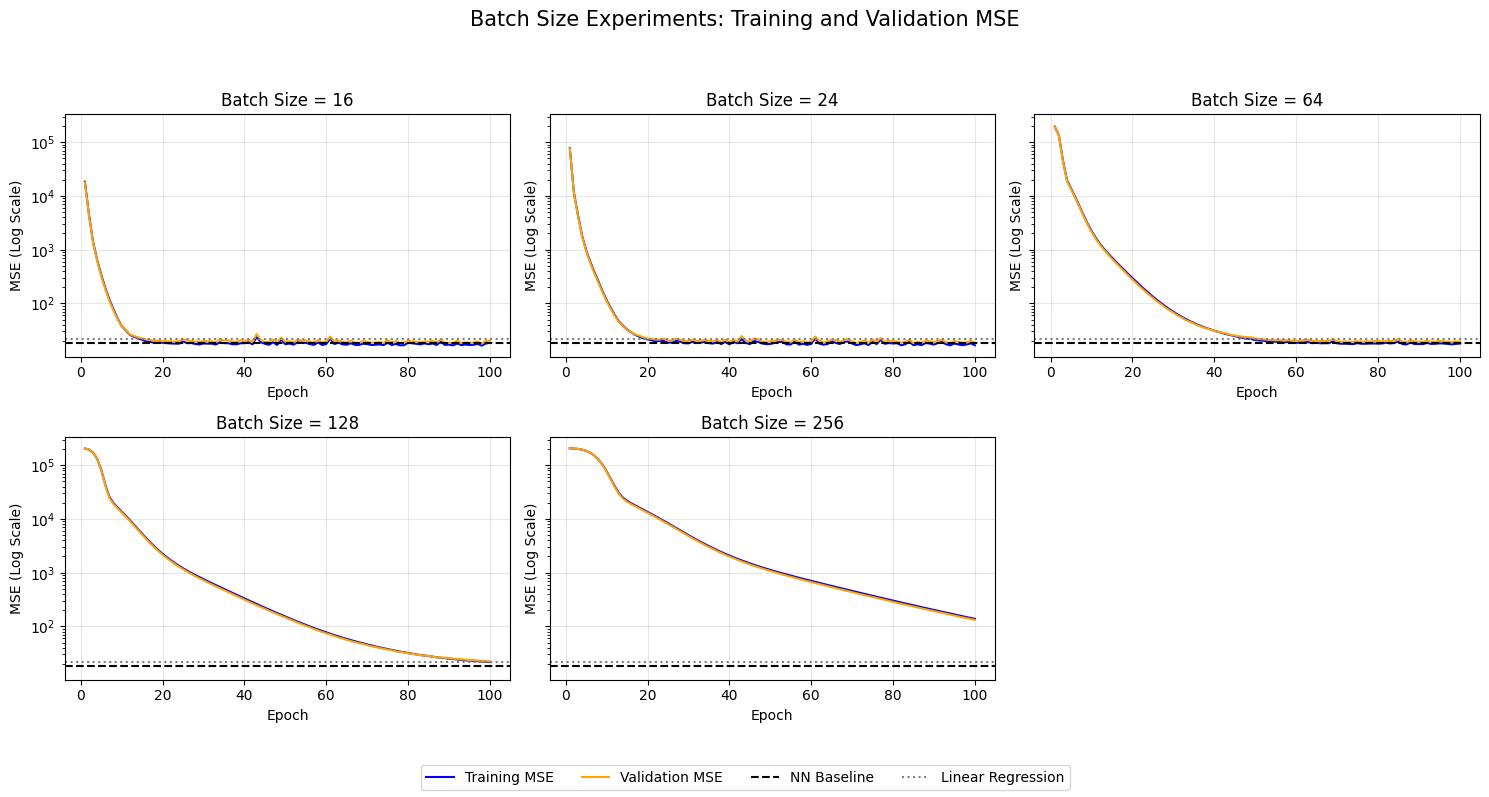

In [323]:
import matplotlib.pyplot as plt

# Batch sizes
batch_sizes = [16, 24, 64, 128, 256]

# Get results
batch_lookup = {
    r["Batch Size"]: r
    for r in batch_results
}

# Create subplots
fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 8),
    sharey=True
)

axes = axes.flatten()

for i, bs in enumerate(batch_sizes):

    result = batch_lookup[bs]

    epochs = range(1, len(result["Train Losses"]) + 1)

    # Training MSE
    axes[i].plot(
        epochs,
        result["Train Losses"],
        color="blue",
        label="Training MSE"
    )

    # Validation MSE
    axes[i].plot(
        epochs,
        result["Val Losses"],
        color="orange",
        label="Validation MSE"
    )

    # Neural Network baseline
    axes[i].axhline(
        nn_val_mse,
        color="black",
        linestyle="--",
        label="NN Baseline"
    )

    # Linear Regression reference
    axes[i].axhline(
        linear_val_mse,
        color="gray",
        linestyle=":",
        label="Linear Regression"
    )

    axes[i].set_title(f"Batch Size = {bs}")
    axes[i].set_xlabel("Epoch")
    axes[i].set_ylabel("MSE (Log Scale)")
    axes[i].set_yscale("log")
    axes[i].grid(True, alpha=0.3)

# Hide the empty subplot
axes[5].axis("off")

# Shared legend
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=4
)

fig.suptitle(
    "Batch Size Experiments: Training and Validation MSE",
    fontsize=15
)

plt.tight_layout(rect=[0, 0.07, 1, 0.94])
plt.show()

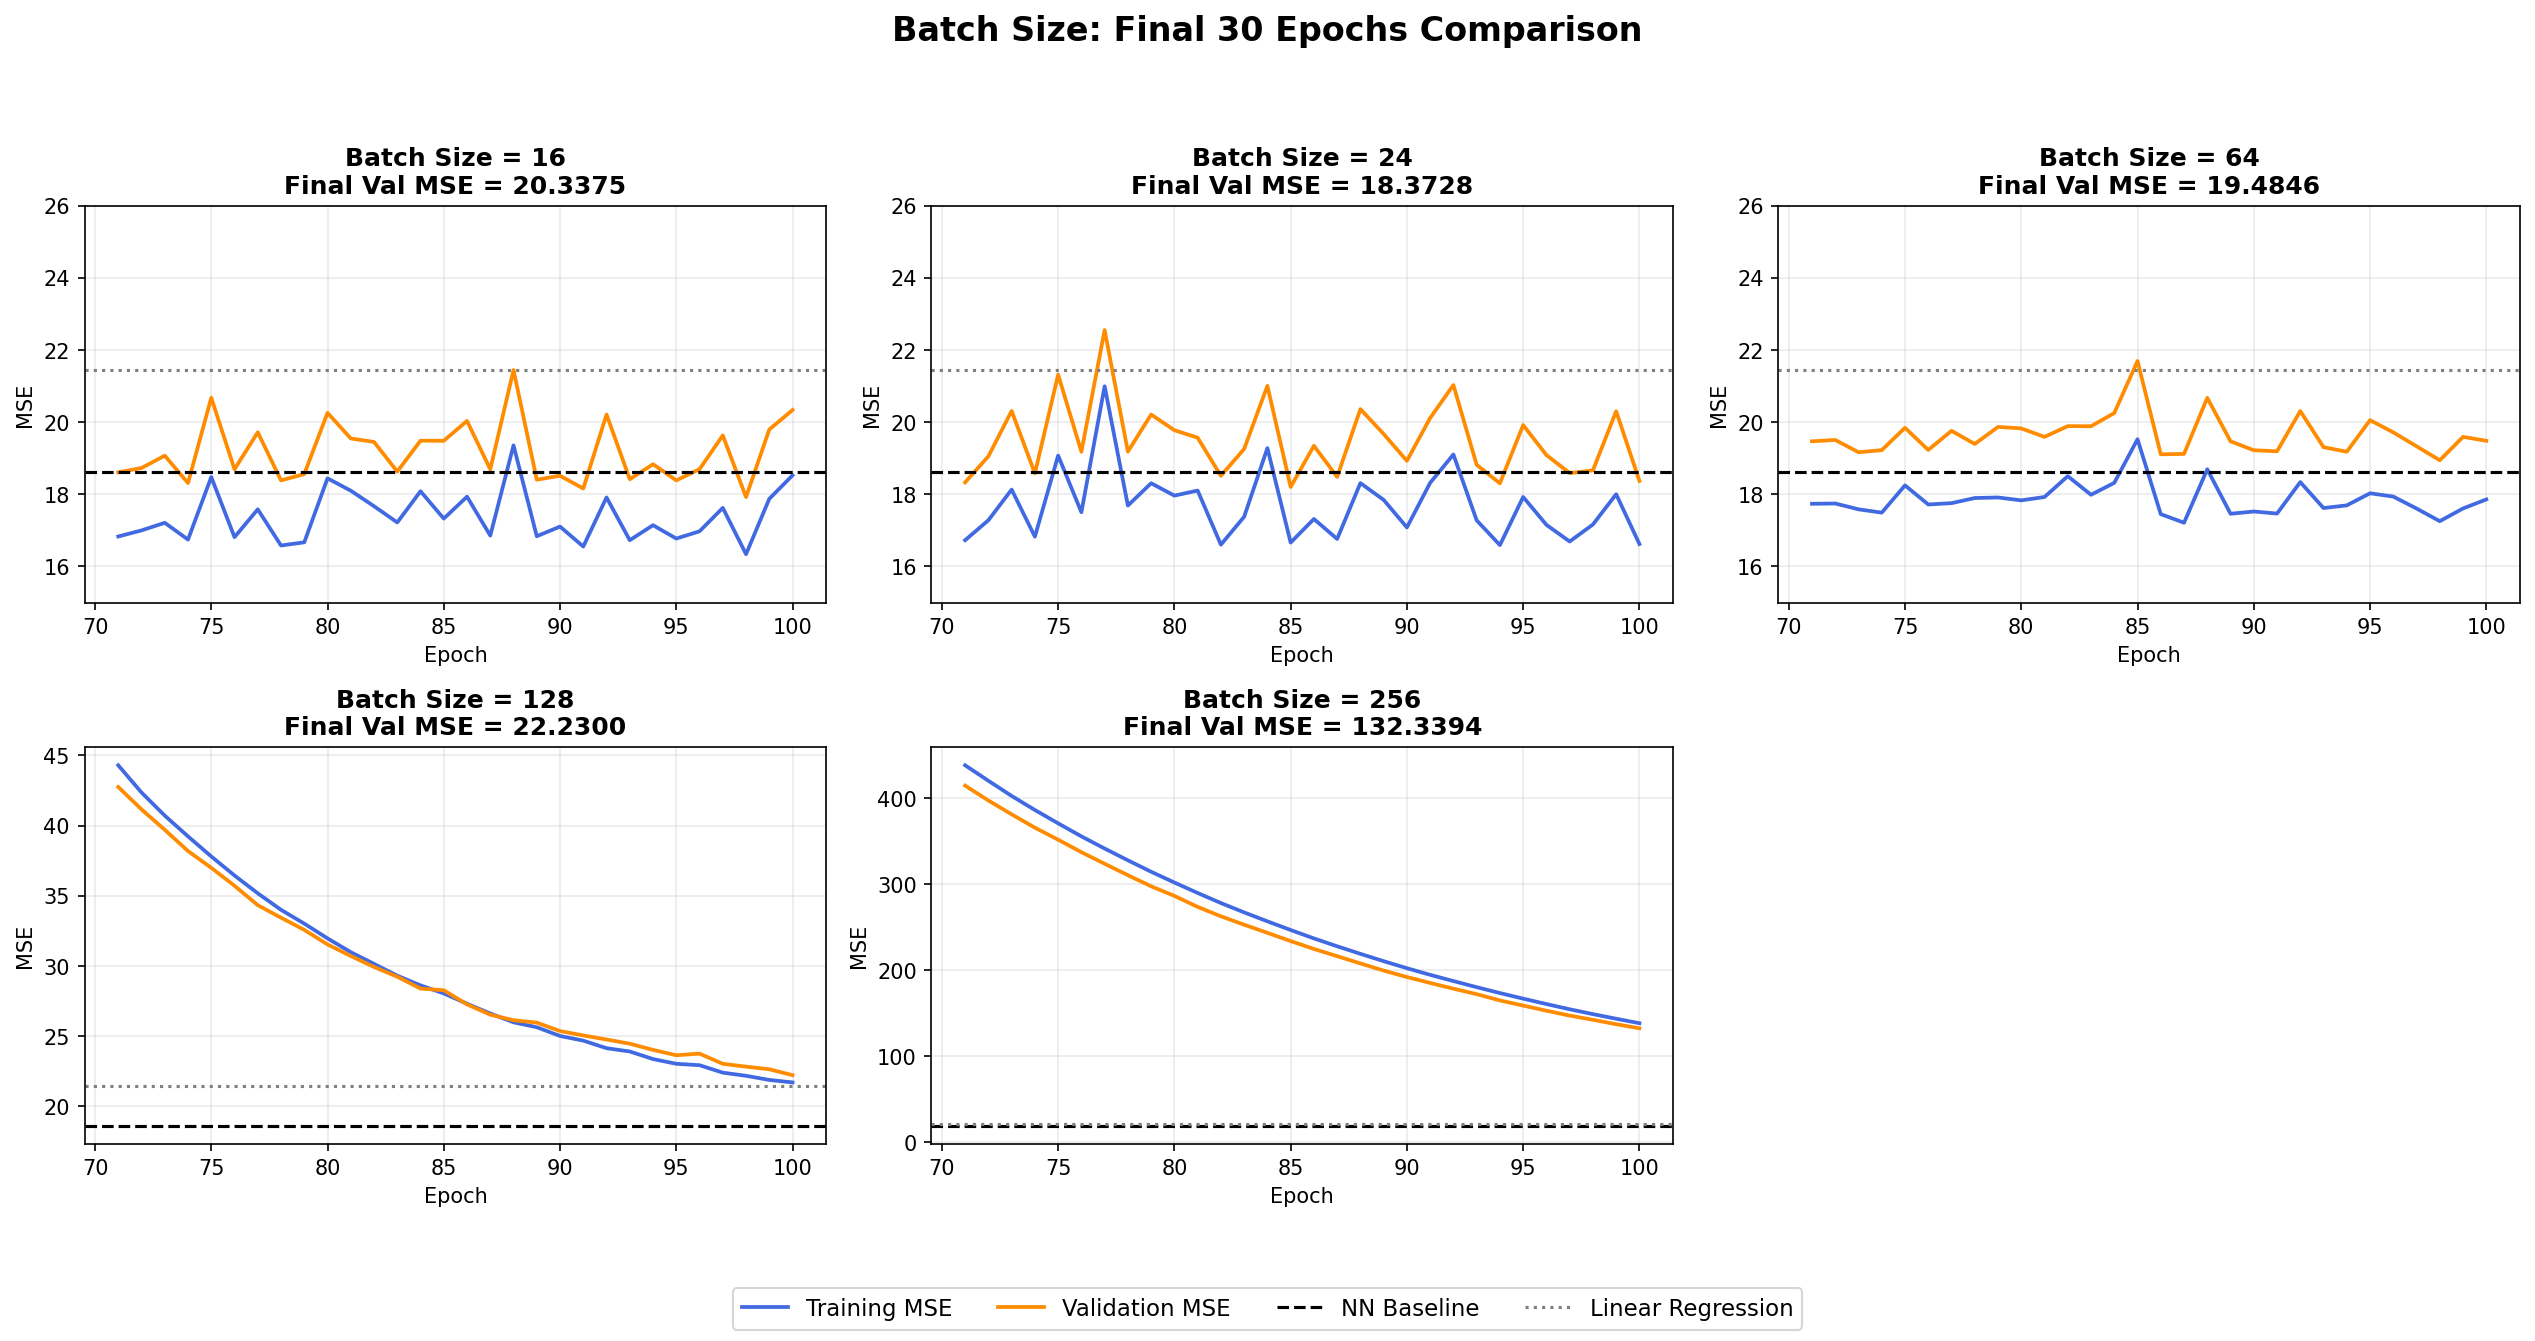

In [349]:

import numpy as np
import matplotlib.pyplot as plt

batch_sizes = [16, 24, 64, 128, 256]

batch_lookup = {
    r["Batch Size"]: r
    for r in batch_results
}

fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 9),
    dpi=150
)

axes = axes.flatten()

for i, bs in enumerate(batch_sizes):

    r = batch_lookup[bs]

    # Last 30 epochs only
    train = np.array(r["Train Losses"][-30:])
    val = np.array(r["Val Losses"][-30:])

    epochs = np.arange(
        len(r["Val Losses"]) - len(val) + 1,
        len(r["Val Losses"]) + 1
    )

    ax = axes[i]

    ax.plot(
        epochs, train,
        color="royalblue",
        linewidth=1.8,
        label="Training MSE"
    )

    ax.plot(
        epochs, val,
        color="darkorange",
        linewidth=1.8,
        label="Validation MSE"
    )

    ax.axhline(
        nn_val_mse,
        color="black",
        linestyle="--",
        label="NN Baseline"
    )

    ax.axhline(
        linear_val_mse,
        color="gray",
        linestyle=":",
        label="Linear Regression"
    )

    ax.set_title(
        f"Batch Size = {bs}\nFinal Val MSE = {val[-1]:.4f}",
        fontsize=12,
        fontweight="bold"
    )

    # Same scale for comparable small batches
    if bs in [16, 24, 64]:
        ax.set_ylim(15, 26)

    # Larger batches use their own scale
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE")
    ax.grid(True, alpha=0.25)

axes[5].axis("off")

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles, labels,
    loc="lower center",
    ncol=4,
    fontsize=11
)

fig.suptitle(
    "Batch Size: Final 30 Epochs Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0.08, 1, 0.94])

plt.savefig(
    "batch_size_clear.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


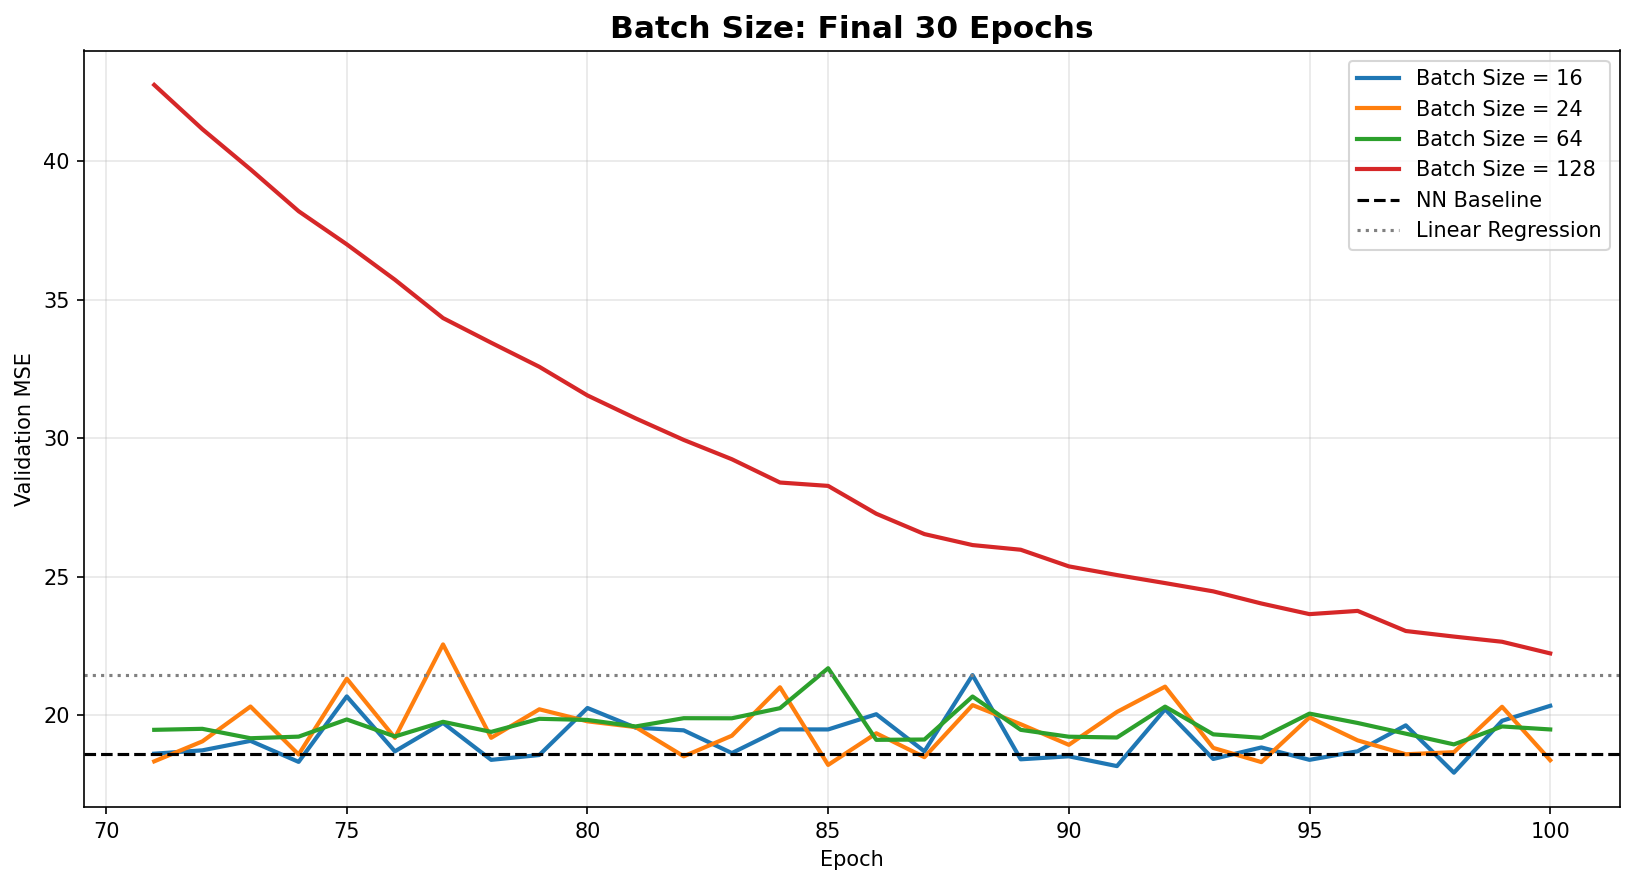

In [324]:

import numpy as np
import matplotlib.pyplot as plt

# Selected batch sizes
selected_sizes = [16, 24, 64, 128]

# Get saved experiment results
batch_lookup = {
    r["Batch Size"]: r
    for r in batch_results
}

plt.figure(figsize=(11, 6), dpi=150)

for bs in selected_sizes:

    r = batch_lookup[bs]

    val_losses = np.array(r["Val Losses"])

    # Select only the last 30 epochs
    last_30 = val_losses[-30:]

    epochs = np.arange(
        len(val_losses) - len(last_30) + 1,
        len(val_losses) + 1
    )

    plt.plot(
        epochs,
        last_30,
        linewidth=2,
        label=f"Batch Size = {bs}"
    )

# NN Baseline
plt.axhline(
    nn_val_mse,
    color="black",
    linestyle="--",
    label="NN Baseline"
)

# Linear Regression
plt.axhline(
    linear_val_mse,
    color="gray",
    linestyle=":",
    label="Linear Regression"
)

plt.xlabel("Epoch")
plt.ylabel("Validation MSE")

plt.title(
    "Batch Size: Final 30 Epochs",
    fontsize=15,
    fontweight="bold"
)

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

# Save for report
plt.savefig(
    "batch_size_final_30.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## <font color="#3B82F6">Depth and Width</font>


In [350]:
import torch
import torch.nn as nn
import pandas as pd
import time

from torch.utils.data import DataLoader

architecture_results = {}

def run_architecture_experiment(hidden_layers):

    # Same random seed for all experiments
    torch.manual_seed(42)

    generator = torch.Generator().manual_seed(42)

    train_loader = DataLoader(
        train_dataset,
        batch_size=32,
        shuffle=True,
        generator=generator
    )

    # Build model
    layers = []
    input_size = 4

    for neurons in hidden_layers:
        layers.append(nn.Linear(input_size, neurons))
        layers.append(nn.ReLU())
        input_size = neurons

    layers.append(nn.Linear(input_size, 1))

    model = nn.Sequential(*layers).to(device)

    # Fixed settings
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    criterion = nn.MSELoss()

    train_losses = []
    val_losses = []

    start_time = time.perf_counter()

    # Training
    for epoch in range(100):

        model.train()

        for xb, yb in train_loader:

            xb = xb.to(device)
            yb = yb.to(device).reshape(-1, 1)

            optimizer.zero_grad()

            predictions = model(xb)
            loss = criterion(predictions, yb)

            loss.backward()
            optimizer.step()

        # Evaluation
        model.eval()

        with torch.no_grad():

            train_loss = criterion(
                model(X_train_tensor.to(device)),
                y_train_tensor.to(device).reshape(-1, 1)
            ).item()

            val_loss = criterion(
                model(X_val_tensor.to(device)),
                y_val_tensor.to(device).reshape(-1, 1)
            ).item()

        train_losses.append(train_loss)
        val_losses.append(val_loss)

    training_time = time.perf_counter() - start_time

    return {
        "Architecture": hidden_layers,
        "Train MSE": train_losses[-1],
        "Val MSE": val_losses[-1],
        "Time (s)": training_time,
        "Epochs Completed": 100,
        "Train Losses": train_losses,
        "Val Losses": val_losses
    }


# Display and save each result
def run_and_save_architecture(name, hidden_layers):

    result = run_architecture_experiment(hidden_layers)

    architecture_results[name] = result

    print("Architecture:", result["Architecture"])
    print(f"Training MSE: {result['Train MSE']:.4f}")
    print(f"Validation MSE: {result['Val MSE']:.4f}")
    print(f"Training Time: {result['Time (s)']:.2f} seconds")
    print("Epochs Completed:", result["Epochs Completed"])

###Experiment 1 — Width [32, 32]

In [351]:
# Depth & Width Experiment 1

run_and_save_architecture("Experiment 1", [32, 32])

Architecture: [32, 32]
Training MSE: 18.4073
Validation MSE: 19.9251
Training Time: 27.71 seconds
Epochs Completed: 100


###Experiment 2 — Width [128, 32]

In [352]:
# Depth & Width Experiment 2

run_and_save_architecture("Experiment 2", [128, 32])

Architecture: [128, 32]
Training MSE: 16.1573
Validation MSE: 17.9696
Training Time: 28.98 seconds
Epochs Completed: 100


###Experiment 3 — Width [64, 64]

In [353]:
# Depth & Width Experiment 3

run_and_save_architecture("Experiment 3", [64, 64])

Architecture: [64, 64]
Training MSE: 16.5616
Validation MSE: 18.3218
Training Time: 28.98 seconds
Epochs Completed: 100


###Experiment 4 — Width [64, 16]

In [354]:
# Depth & Width Experiment 4

result = run_architecture_experiment([64, 16])

architecture_results["Experiment 4"] = result

print("Architecture:", result["Architecture"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")
print("Epochs Completed:", result["Epochs Completed"])


Architecture: [64, 16]
Training MSE: 17.4270
Validation MSE: 19.2471
Training Time: 27.39 seconds
Epochs Completed: 100


###Experiment 5 — One Hidden Layer

In [355]:
# Depth & Width Experiment 5

run_and_save_architecture("Experiment 5", [64])

Architecture: [64]
Training MSE: 18.4714
Validation MSE: 19.4936
Training Time: 22.95 seconds
Epochs Completed: 100


###Experiment 6 — Three Hidden Layers

In [356]:
# Depth & Width Experiment 6

run_and_save_architecture("Experiment 6", [64, 32, 16])

Architecture: [64, 32, 16]
Training MSE: 16.1674
Validation MSE: 17.9470
Training Time: 32.13 seconds
Epochs Completed: 100


 ### Experiment 7 - Third Hidden Layer Width

In [357]:


# Depth & Width Experiment 7
result = run_architecture_experiment([64, 32, 8])

architecture_results["Experiment 7"] = result

print("Architecture:", result["Architecture"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")
print("Epochs Completed:", result["Epochs Completed"])


Architecture: [64, 32, 8]
Training MSE: 16.5627
Validation MSE: 18.3147
Training Time: 31.90 seconds
Epochs Completed: 100


###Experiment 8 - Four Hidden Layers

In [358]:
# Depth & Width Experiment 8

result = run_architecture_experiment([64, 32, 16, 8])

architecture_results["Experiment 8"] = result

print("Architecture:", result["Architecture"])
print(f"Training MSE: {result['Train MSE']:.4f}")
print(f"Validation MSE: {result['Val MSE']:.4f}")
print(f"Training Time: {result['Time (s)']:.2f} seconds")
print("Epochs Completed:", result["Epochs Completed"])



Architecture: [64, 32, 16, 8]
Training MSE: 16.1852
Validation MSE: 18.0899
Training Time: 36.21 seconds
Epochs Completed: 100


In [361]:
# Depth & Width Results Table


rows = [{
    "Run": "Baseline",
    "Architecture": "[64, 32]",
    "Train MSE": nn_train_mse,
    "Val MSE": nn_val_mse,
    "Time (s)": None,
    "Epochs": 100
}]

for name, result in architecture_results.items():
    rows.append({
        "Run": name,
        "Architecture": str(result["Architecture"]),
        "Train MSE": result["Train MSE"],
        "Val MSE": result["Val MSE"],
        "Time (s)": result["Time (s)"],
        "Epochs": result["Epochs Completed"]
    })

architecture_table = pd.DataFrame(rows)

display(architecture_table.round({
    "Train MSE": 4,
    "Val MSE": 4,
    "Time (s)": 2
}))

,Run,Architecture,Train MSE,Val MSE,Time (s),Epochs
0,Baseline,"[64, 32]",16.7957,18.6084,NaN,100
1,Experiment 1,"[32, 32]",18.4073,19.9251,27.71,100
2,Experiment 2,"[128, 32]",16.1573,17.9696,28.98,100
3,Experiment 3,"[64, 64]",16.5616,18.3218,28.98,100
4,Experiment 4,[64],18.4714,19.4936,22.95,100
5,Experiment 5,"[64, 32, 16]",16.1674,17.9470,32.13,100
6,Experiment 6,"[64, 16]",17.4270,19.2471,27.39,100
7,Experiment 7,"[64, 32, 16, 8]",16.1852,18.0899,36.21,100
8,Experiment 8,"[64, 32, 8]",16.5627,18.3147,31.90,100


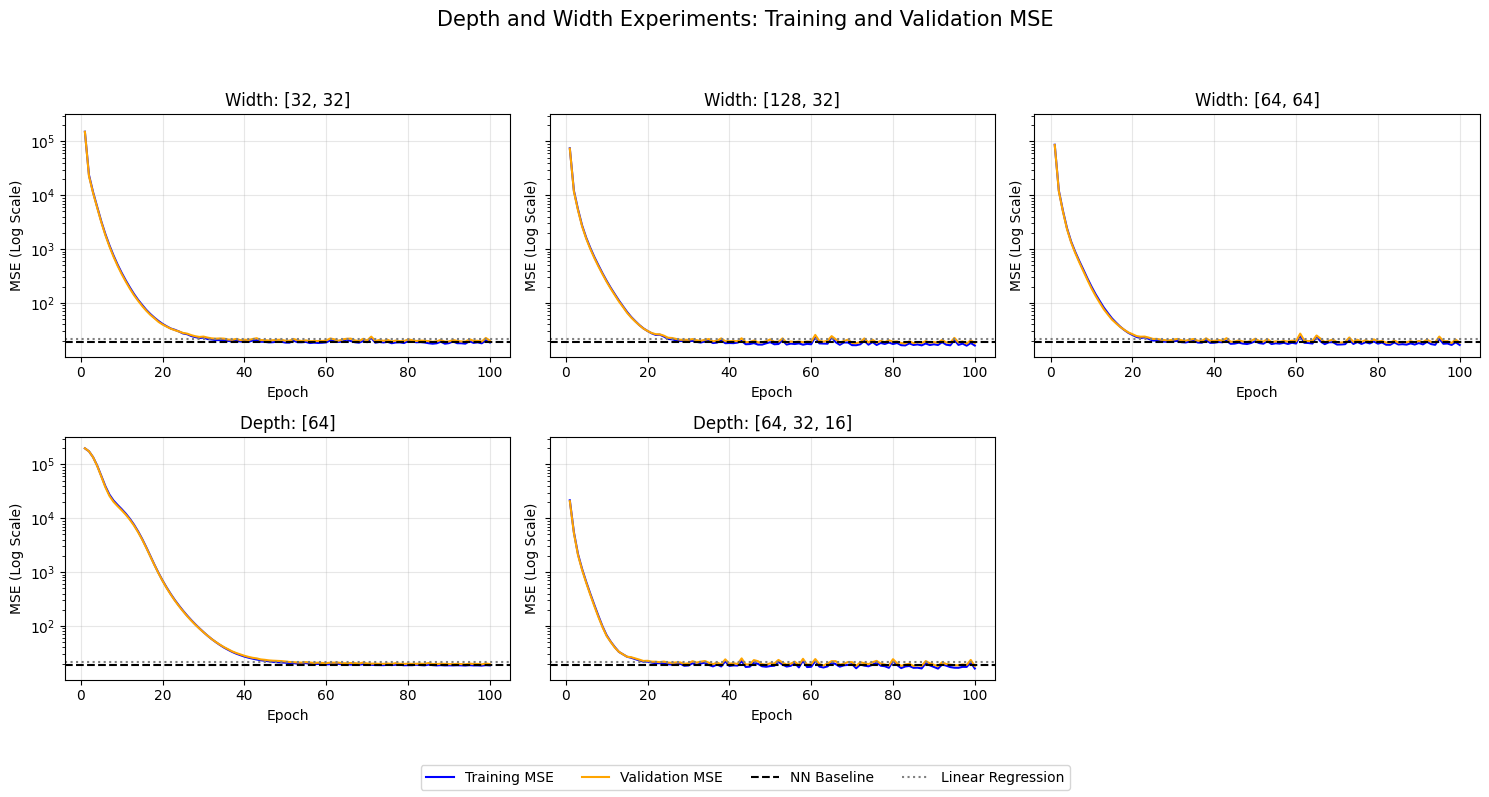

In [335]:
import matplotlib.pyplot as plt

# Depth and Width experiments
experiments = [
    ("Experiment 1", "Width"),
    ("Experiment 2", "Width"),
    ("Experiment 3", "Width"),
    ("Experiment 4", "Depth"),
    ("Experiment 5", "Depth")
]

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 8),
    sharey=True
)

axes = axes.flatten()

for i, (name, category) in enumerate(experiments):

    result = architecture_results[name]

    epochs = range(1, len(result["Train Losses"]) + 1)

    # Training MSE
    axes[i].plot(
        epochs,
        result["Train Losses"],
        color="blue",
        label="Training MSE"
    )

    # Validation MSE
    axes[i].plot(
        epochs,
        result["Val Losses"],
        color="orange",
        label="Validation MSE"
    )

    # Neural Network baseline
    axes[i].axhline(
        nn_val_mse,
        color="black",
        linestyle="--",
        label="NN Baseline"
    )

    # Linear Regression reference
    axes[i].axhline(
        linear_val_mse,
        color="gray",
        linestyle=":",
        label="Linear Regression"
    )

    axes[i].set_title(
        f"{category}: {result['Architecture']}"
    )

    axes[i].set_xlabel("Epoch")
    axes[i].set_ylabel("MSE (Log Scale)")
    axes[i].set_yscale("log")
    axes[i].grid(True, alpha=0.3)

# Hide empty subplot
axes[5].axis("off")

# Shared legend
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=4
)

fig.suptitle(
    "Depth and Width Experiments: Training and Validation MSE",
    fontsize=15
)

plt.tight_layout(rect=[0, 0.07, 1, 0.94])
plt.show()

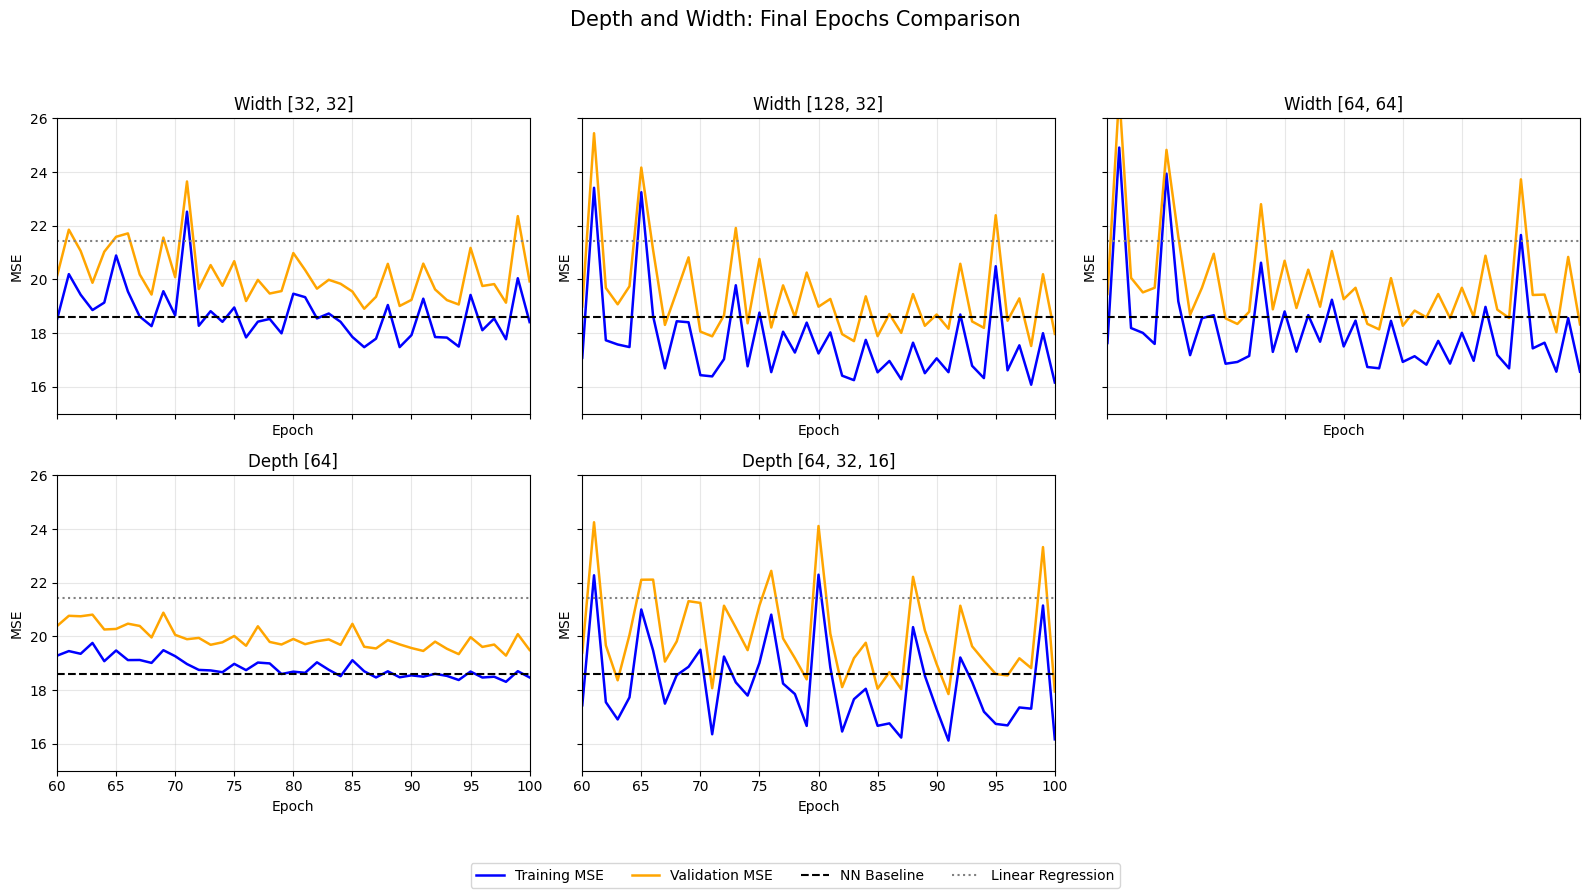

In [336]:
import matplotlib.pyplot as plt

experiments = [
    ("Experiment 1", "Width [32, 32]"),
    ("Experiment 2", "Width [128, 32]"),
    ("Experiment 3", "Width [64, 64]"),
    ("Experiment 4", "Depth [64]"),
    ("Experiment 5", "Depth [64, 32, 16]")
]

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 9),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

for i, (name, title) in enumerate(experiments):

    result = architecture_results[name]

    epochs = range(1, len(result["Train Losses"]) + 1)

    # Training MSE
    axes[i].plot(
        epochs,
        result["Train Losses"],
        color="blue",
        linewidth=1.8,
        label="Training MSE"
    )

    # Validation MSE
    axes[i].plot(
        epochs,
        result["Val Losses"],
        color="orange",
        linewidth=1.8,
        label="Validation MSE"
    )

    # NN Baseline
    axes[i].axhline(
        nn_val_mse,
        color="black",
        linestyle="--",
        label="NN Baseline"
    )

    # Linear Regression
    axes[i].axhline(
        linear_val_mse,
        color="gray",
        linestyle=":",
        label="Linear Regression"
    )

    # Zoom into final epochs
    axes[i].set_xlim(60, 100)
    axes[i].set_ylim(15, 26)

    axes[i].set_title(title)
    axes[i].set_xlabel("Epoch")
    axes[i].set_ylabel("MSE")
    axes[i].grid(True, alpha=0.3)

# Hide empty subplot
axes[5].axis("off")

# Shared legend
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=4
)

fig.suptitle(
    "Depth and Width: Final Epochs Comparison",
    fontsize=15
)

plt.tight_layout(rect=[0, 0.07, 1, 0.94])
plt.show()

## <font color="#3B82F6">Loss Function</font>


In [337]:
import time
import torch
import torch.nn as nn
from torch.utils.data import DataLoader


def run_loss_experiment(training_loss_fn):
    # Same initial weights and batch order as the baseline
    torch.manual_seed(42)
    generator = torch.Generator().manual_seed(42)

    loader = DataLoader(
        train_dataset,
        batch_size=32,
        shuffle=True,
        generator=generator
    )

    model = nn.Sequential(
        nn.Linear(4, 64),
        nn.ReLU(),
        nn.Linear(64, 32),
        nn.ReLU(),
        nn.Linear(32, 1)
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    mse_metric = nn.MSELoss()

    train_mse_history = []
    val_mse_history = []
    start_time = time.perf_counter()

    for epoch in range(100):
        model.train()

        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()
            predictions = model(xb)
            loss = training_loss_fn(predictions, yb)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            train_predictions = model(X_train_tensor.to(device))
            val_predictions = model(X_val_tensor.to(device))

            train_mse = mse_metric(train_predictions, y_train_tensor.to(device))
            val_mse = mse_metric(val_predictions, y_val_tensor.to(device))

        train_mse_history.append(train_mse.item())
        val_mse_history.append(val_mse.item())

    return {
        "Train MSE": train_mse_history[-1],
        "Val MSE": val_mse_history[-1],
        "Time (s)": time.perf_counter() - start_time,
        "Train MSE History": train_mse_history,
        "Val MSE History": val_mse_history
    }

###Loss Function Experiment 1 - L1 Loss


In [338]:
# Loss Function Experiment 1 - L1 Loss
l1_result = run_loss_experiment(nn.L1Loss())

print(f"Training MSE:   {l1_result['Train MSE']:.4f}")
print(f"Validation MSE: {l1_result['Val MSE']:.4f}")
print(f"Training time:  {l1_result['Time (s)']:.2f} seconds")

Training MSE:   19.2859
Validation MSE: 21.0570
Training time:  28.52 seconds


###Loss Function Experiment 2 - Huber Loss, delta = 1

In [339]:
# Loss Function Experiment 2 - Huber Loss, delta = 1

huber_1_result = run_loss_experiment(nn.HuberLoss(delta=1.0))

print(f"Training MSE:   {huber_1_result['Train MSE']:.4f}")
print(f"Validation MSE: {huber_1_result['Val MSE']:.4f}")
print(f"Training time:  {huber_1_result['Time (s)']:.2f} seconds")

Training MSE:   19.4388
Validation MSE: 21.1215
Training time:  27.97 seconds


###Loss Function Experiment 3 - Huber Loss, delta = 2

In [340]:
# Loss Function Experiment 3 - Huber Loss, delta = 2

huber_2_result = run_loss_experiment(nn.HuberLoss(delta=2.0))

print(f"Training MSE:   {huber_2_result['Train MSE']:.4f}")
print(f"Validation MSE: {huber_2_result['Val MSE']:.4f}")
print(f"Training time:  {huber_2_result['Time (s)']:.2f} seconds")

Training MSE:   19.0092
Validation MSE: 20.6920
Training time:  28.07 seconds


###Loss Function Experiment 4 - Huber Loss, delta = 4


In [341]:
# Loss Function Experiment 4 - Huber Loss, delta = 4

huber_4_result = run_loss_experiment(nn.HuberLoss(delta=4.0))

print(f"Training MSE:   {huber_4_result['Train MSE']:.4f}")
print(f"Validation MSE: {huber_4_result['Val MSE']:.4f}")
print(f"Training time:  {huber_4_result['Time (s)']:.2f} seconds")

Training MSE:   17.6375
Validation MSE: 19.3618
Training time:  28.54 seconds


####Loss Function Experiment 5 - Huber Loss, delta = 8


In [342]:
# Loss Function Experiment 5 - Huber Loss, delta = 8

huber_8_result = run_loss_experiment(nn.HuberLoss(delta=8.0))

# Display results
print(f"Training MSE:   {huber_8_result['Train MSE']:.4f}")
print(f"Validation MSE: {huber_8_result['Val MSE']:.4f}")
print(f"Training time:  {huber_8_result['Time (s)']:.2f} seconds")

Training MSE:   16.9638
Validation MSE: 18.6934
Training time:  28.09 seconds


###Loss Function Experiment 6 - Huber Loss, delta = 16


In [343]:
# Loss Function Experiment 6 - Huber Loss, delta = 16

huber_16_result = run_loss_experiment(nn.HuberLoss(delta=16.0))

# Display results
print(f"Training MSE:   {huber_16_result['Train MSE']:.4f}")
print(f"Validation MSE: {huber_16_result['Val MSE']:.4f}")
print(f"Training time:  {huber_16_result['Time (s)']:.2f} seconds")

Training MSE:   17.0982
Validation MSE: 18.8006
Training time:  27.69 seconds


###  Loss Function Experiments - Results Summary

In [344]:
# Loss Function Experiments - Results Summary

import pandas as pd

loss_runs = [
    ("Experiment 1", "L1", None, l1_result),
    ("Experiment 2", "Huber", 1, huber_1_result),
    ("Experiment 3", "Huber", 2, huber_2_result),
    ("Experiment 4", "Huber", 4, huber_4_result),
    ("Experiment 5", "Huber", 8, huber_8_result),
    ("Experiment 6", "Huber", 16, huber_16_result),
]

rows = [{
    "Run": "Baseline",
    "Training Loss": "MSE",
    "Delta": None,
    "Train MSE": 16.7957,
    "Validation MSE": 18.6084,
    "Time (s)": None,
}]

for run, loss_name, delta, result in loss_runs:
    rows.append({
        "Run": run,
        "Training Loss": loss_name,
        "Delta": delta,
        "Train MSE": result["Train MSE"],
        "Validation MSE": result["Val MSE"],
        "Time (s)": result["Time (s)"],
    })

loss_results_table = pd.DataFrame(rows)

display(
    loss_results_table.style.hide(axis="index").format(
        {
            "Delta": "{:.0f}",
            "Train MSE": "{:.4f}",
            "Validation MSE": "{:.4f}",
            "Time (s)": "{:.2f}",
        },
        na_rep="—",
    )
)

Run,Training Loss,Delta,Train MSE,Validation MSE,Time (s)
Baseline,MSE,—,16.7957,18.6084,—
Experiment 1,L1,—,19.2859,21.0570,28.52
Experiment 2,Huber,1,19.4388,21.1215,27.97
Experiment 3,Huber,2,19.0092,20.6920,28.07
Experiment 4,Huber,4,17.6375,19.3618,28.54
Experiment 5,Huber,8,16.9638,18.6934,28.09
Experiment 6,Huber,16,17.0982,18.8006,27.69


###Loss Function Experiments - Training and Validation MSE Curves


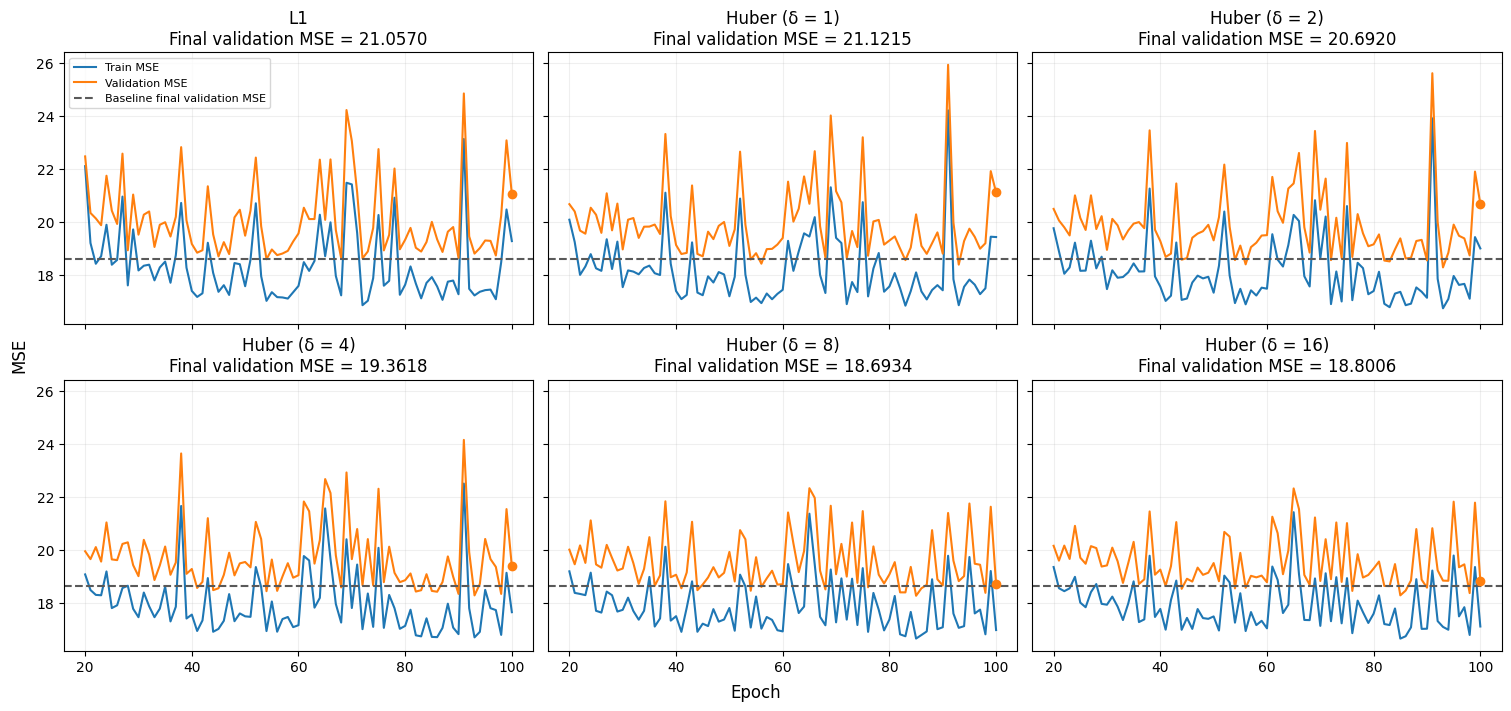

In [345]:
# Loss Function Experiments - Training and Validation MSE Curves

import matplotlib.pyplot as plt

# Loss Function Experiments - MSE Curves by Experiment

import matplotlib.pyplot as plt

start_epoch = 20
baseline_val_mse = 18.6084

fig, axes = plt.subplots(
    2, 3, figsize=(15, 7), sharex=True, sharey=True,
    layout="constrained"
)

for ax, (_, loss_name, delta, result) in zip(axes.flat, loss_runs):
    label = loss_name if delta is None else f"Huber (δ = {delta})"

    train_history = result["Train MSE History"]
    val_history = result["Val MSE History"]
    epochs = range(start_epoch, len(val_history) + 1)

    ax.plot(
        epochs, train_history[start_epoch - 1:],
        color="tab:blue", label="Train MSE"
    )
    ax.plot(
        epochs, val_history[start_epoch - 1:],
        color="tab:orange", label="Validation MSE"
    )
    ax.axhline(
        baseline_val_mse, color="0.35", linestyle="--",
        label="Baseline final validation MSE"
    )
    ax.scatter(len(val_history), val_history[-1], color="tab:orange", zorder=3)

    ax.set_title(f"{label}\nFinal validation MSE = {val_history[-1]:.4f}")
    ax.set_xticks([20, 40, 60, 80, 100])
    ax.grid(alpha=0.2)

axes[0, 0].legend(fontsize=8)
fig.supxlabel("Epoch")
fig.supylabel("MSE")
plt.show()

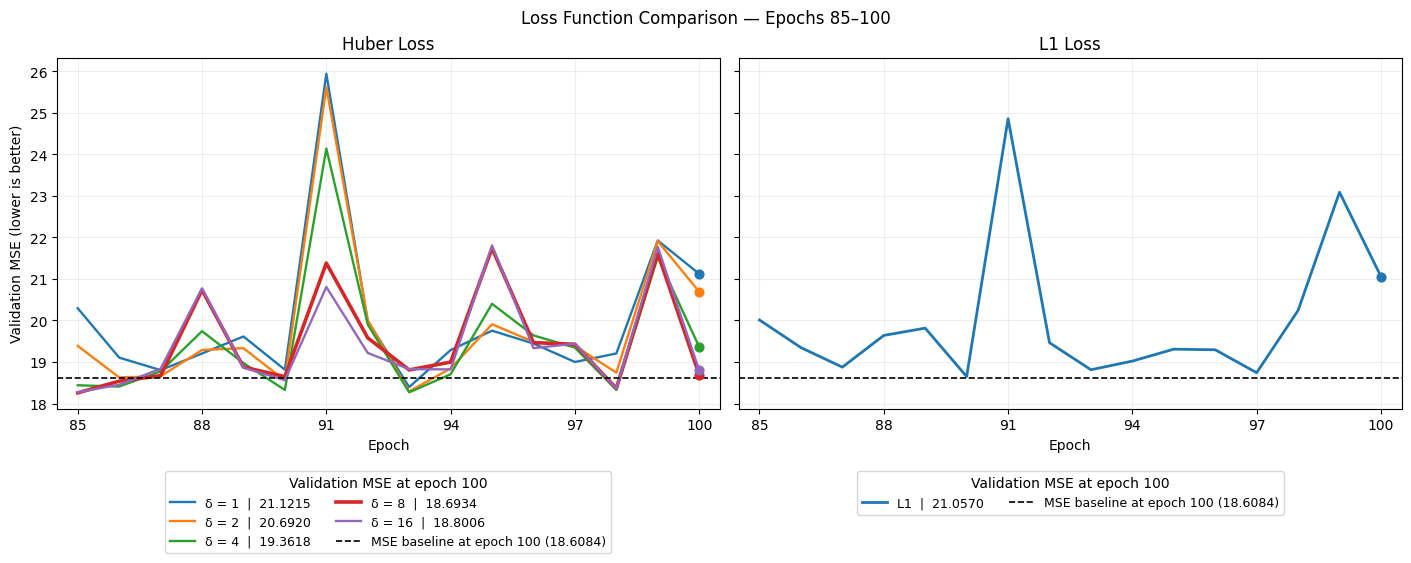

In [346]:
# Zoom in on epochs 85–100 to show differences in validation MSE near the end of training.
# Each dot marks a run's final score at epoch 100.
# The dashed line marks the MSE baseline's final score (18.6084).

import matplotlib.pyplot as plt

first_epoch = 85
last_epoch = 100
baseline_mse = 18.6084

fig, (huber_ax, l1_ax) = plt.subplots(
    1, 2, figsize=(14, 5.5), sharex=True, sharey=True,
    layout="constrained",
)

for _, loss_name, delta, result in loss_runs:
    history = result["Val MSE History"]
    epochs = range(first_epoch, last_epoch + 1)
    values = history[first_epoch - 1:last_epoch]

    if loss_name == "Huber":
        ax = huber_ax
        label = f"δ = {delta}  |  {values[-1]:.4f}"
        linewidth = 2.6 if delta == 8 else 1.7
    else:
        ax = l1_ax
        label = f"L1  |  {values[-1]:.4f}"
        linewidth = 2

    line, = ax.plot(epochs, values, linewidth=linewidth, label=label)
    ax.scatter(last_epoch, values[-1], color=line.get_color(), s=40, zorder=3)

for ax, title in [(huber_ax, "Huber Loss"), (l1_ax, "L1 Loss")]:
    ax.axhline(
        baseline_mse, color="black", linestyle="--", linewidth=1.2,
        label=f"MSE baseline at epoch 100 ({baseline_mse:.4f})",
    )
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_xticks([85, 88, 91, 94, 97, 100])
    ax.set_xlim(84.5, 100.5)
    ax.grid(alpha=0.2)
    ax.legend(
        title="Validation MSE at epoch 100",
        loc="upper center", bbox_to_anchor=(0.5, -0.16),
        ncol=2, fontsize=9,
    )

huber_ax.set_ylabel("Validation MSE (lower is better)")
fig.suptitle("Loss Function Comparison — Epochs 85–100")
plt.show()

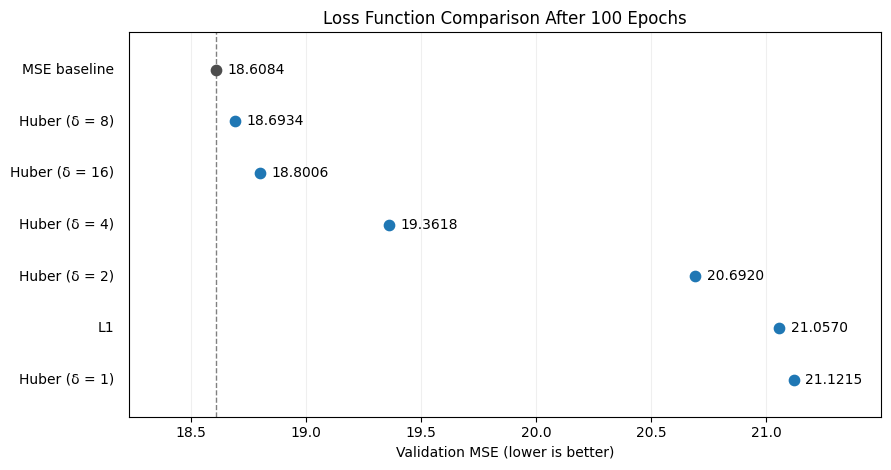

In [347]:
# Loss Function Experiments - Final Validation MSE

import matplotlib.pyplot as plt

comparison = loss_results_table.sort_values("Validation MSE")
baseline_mse = comparison.loc[
    comparison["Run"].eq("Baseline"), "Validation MSE"
].iloc[0]

fig, ax = plt.subplots(figsize=(9, 4.8))

ax.axvline(baseline_mse, color="0.5", linestyle="--", linewidth=1)

for position, (_, row) in enumerate(comparison.iterrows()):
    loss = row["Training Loss"]
    score = row["Validation MSE"]

    if row["Run"] == "Baseline":
        label = "MSE baseline"
        color = "0.3"
    elif loss == "Huber":
        label = f"Huber (δ = {row['Delta']:.0f})"
        color = "tab:blue"
    else:
        label = loss
        color = "tab:blue"

    ax.scatter(score, position, color=color, s=55, zorder=3)
    ax.annotate(
        f"{score:.4f}", (score, position),
        xytext=(8, 0), textcoords="offset points", va="center"
    )
    ax.text(-0.02, position, label, transform=ax.get_yaxis_transform(),
            ha="right", va="center")

ax.set_yticks([])
ax.invert_yaxis()
ax.margins(x=0.15, y=0.12)
ax.set_title("Loss Function Comparison After 100 Epochs")
ax.set_xlabel("Validation MSE (lower is better)")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
plt.show()

# **Experiment Results Table**

In [362]:

# Experiment Results Table - All Experiments

import pandas as pd
import numpy as np

all_rows = []

# Linear Regression Baseline
all_rows.append({
    "Run": "Linear Regression",
    "Topic": "Baseline",
    "Configuration": "Linear Regression",
    "Train MSE": 20.2748,
    "Val MSE": 21.4396,
    "Time (s)": np.nan
})

# Neural Network Baseline
all_rows.append({
    "Run": "Baseline NN",
    "Topic": "Baseline",
    "Configuration": "Adam, LR=0.001, [64, 32], BS=32",
    "Train MSE": nn_train_mse,
    "Val MSE": nn_val_mse,
    "Time (s)": np.nan
})

# Learning Rate Experiments
for _, r in lr_table.iterrows():
    if r["Run"] == "Baseline":
        continue

    all_rows.append({
        "Run": r["Run"],
        "Topic": "Learning Rate",
        "Configuration": f"LR = {r['Learning Rate']:.5f}",
        "Train MSE": r["Train MSE"],
        "Val MSE": r["Val MSE"],
        "Time (s)": r["Time (s)"]
    })

# Optimizer Experiments
for i, r in enumerate(optimizer_results, start=1):
    momentum = r.get("Momentum")

    config = (
        f"{r['Optimizer']}, "
        f"LR = {r['Learning Rate']:.5f}"
    )

    if momentum is not None and pd.notna(momentum):
        config += f", Momentum = {momentum}"

    all_rows.append({
        "Run": f"Experiment {i}",
        "Topic": "Optimizer",
        "Configuration": config,
        "Train MSE": r["Train MSE"],
        "Val MSE": r["Val MSE"],
        "Time (s)": r["Time (s)"]
    })

# Batch Size Experiments
for _, r in batch_table.iterrows():
    if r["Run"] == "Baseline":
        continue

    all_rows.append({
        "Run": r["Run"],
        "Topic": "Batch Size",
        "Configuration": f"Batch Size = {int(r['Batch Size'])}",
        "Train MSE": r["Train MSE"],
        "Val MSE": r["Val MSE"],
        "Time (s)": r["Time (s)"]
    })

# Depth & Width Experiments
# Read directly from the latest saved results
for run, r in architecture_results.items():
    all_rows.append({
        "Run": run,
        "Topic": "Depth & Width",
        "Configuration": f"Architecture = {r['Architecture']}",
        "Train MSE": r["Train MSE"],
        "Val MSE": r["Val MSE"],
        "Time (s)": r["Time (s)"]
    })

# Loss Function Experiments
for _, r in loss_table.iterrows():
    if r["Run"] == "Baseline":
        continue

    if pd.notna(r["Delta"]):
        config = f"{r['Loss Function']}, Delta = {r['Delta']:g}"
    else:
        config = str(r["Loss Function"])

    all_rows.append({
        "Run": r["Run"],
        "Topic": "Loss Function",
        "Configuration": config,
        "Train MSE": r["Train MSE"],
        "Val MSE": r["Val MSE"],
        "Time (s)": r["Time (s)"]
    })

# Create final table
all_results_table = pd.DataFrame(all_rows)

# Identify numerical instability
all_results_table["Status"] = all_results_table[
    ["Train MSE", "Val MSE"]
].apply(
    lambda row: (
        "Valid" if np.isfinite(row).all()
        else "NaN"
    ),
    axis=1
)

# Display
display(
    all_results_table.style.format({
        "Train MSE": "{:.4f}",
        "Val MSE": "{:.4f}",
        "Time (s)": "{:.2f}"
    }, na_rep="—")
)

# Count experiments by topic
experiment_counts = (
    all_results_table[
        all_results_table["Topic"] != "Baseline"
    ]
    .groupby("Topic")
    .size()
)

print("\nExperiments per topic:")
print(experiment_counts.to_string())

print("\nTotal Experiment Rows:", experiment_counts.sum())


,Run,Topic,Configuration,Train MSE,Val MSE,Time (s),Status
0,Linear Regression,Baseline,Linear Regression,20.2748,21.4396,—,Valid
1,Baseline NN,Baseline,"Adam, LR=0.001, [64, 32], BS=32",16.7957,18.6084,—,Valid
2,LR Experiment 1,Learning Rate,LR = 0.00010,31.7889,31.3234,28.31,Valid
3,LR Experiment 2,Learning Rate,LR = 0.00030,17.4802,19.0203,30.17,Valid
4,LR Experiment 3,Learning Rate,LR = 0.00300,17.2582,19.1169,28.55,Valid
5,LR Experiment 4,Learning Rate,LR = 0.01000,21.0044,23.7329,28.08,Valid
6,LR Experiment 5,Learning Rate,LR = 0.03000,31.6638,35.6667,28.51,Valid
7,LR Experiment 6,Learning Rate,LR = 0.00050,17.5269,19.1729,28.41,Valid
8,LR Experiment 7,Learning Rate,LR = 0.00200,16.5886,18.2036,28.39,Valid
9,Experiment 1,Optimizer,"SGD, LR = 0.00100, Momentum = 0.0",—,—,0.77,NaN



Experiments per topic:
Topic
Batch Size       5
Depth & Width    8
Learning Rate    7
Loss Function    6
Optimizer        4

Total Experiment Rows: 30


# **Loss Curves & Results Analysis**

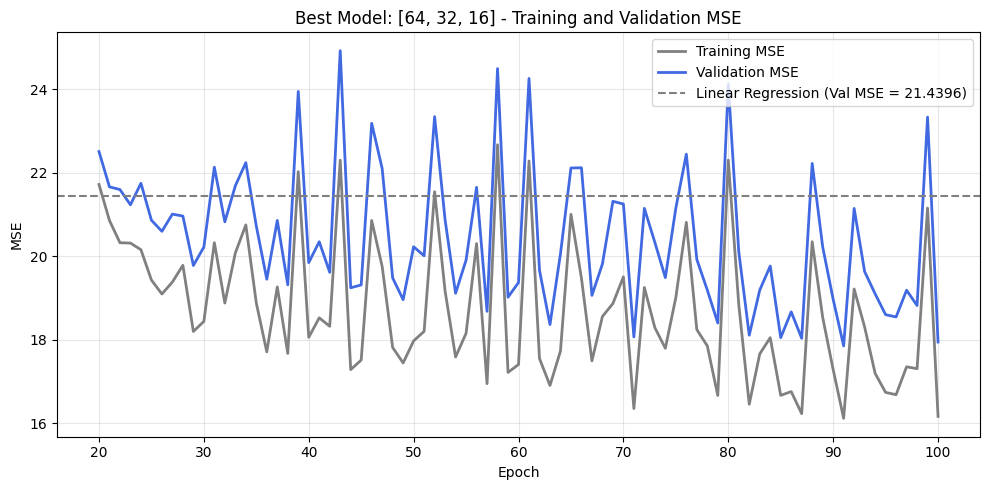

In [364]:

# Best Model - Loss Curves (Professor's Style)

import numpy as np
import matplotlib.pyplot as plt

# Best architecture experiment
best_result = architecture_results["Experiment 5"]

train_losses = best_result["Train Losses"]
val_losses = best_result["Val Losses"]

epochs = np.arange(1, len(train_losses) + 1)

# Zoom into later epochs for better visibility
start_epoch = 20

plt.figure(figsize=(10, 5))

plt.plot(
    epochs[start_epoch - 1:],
    train_losses[start_epoch - 1:],
    label="Training MSE",
    color="gray",
    linewidth=2
)

plt.plot(
    epochs[start_epoch - 1:],
    val_losses[start_epoch - 1:],
    label="Validation MSE",
    color="royalblue",
    linewidth=2
)

plt.axhline(
    y=21.4396,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label="Linear Regression (Val MSE = 21.4396)"
)

plt.title(
    "Best Model: [64, 32, 16] - Training and Validation MSE"
)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


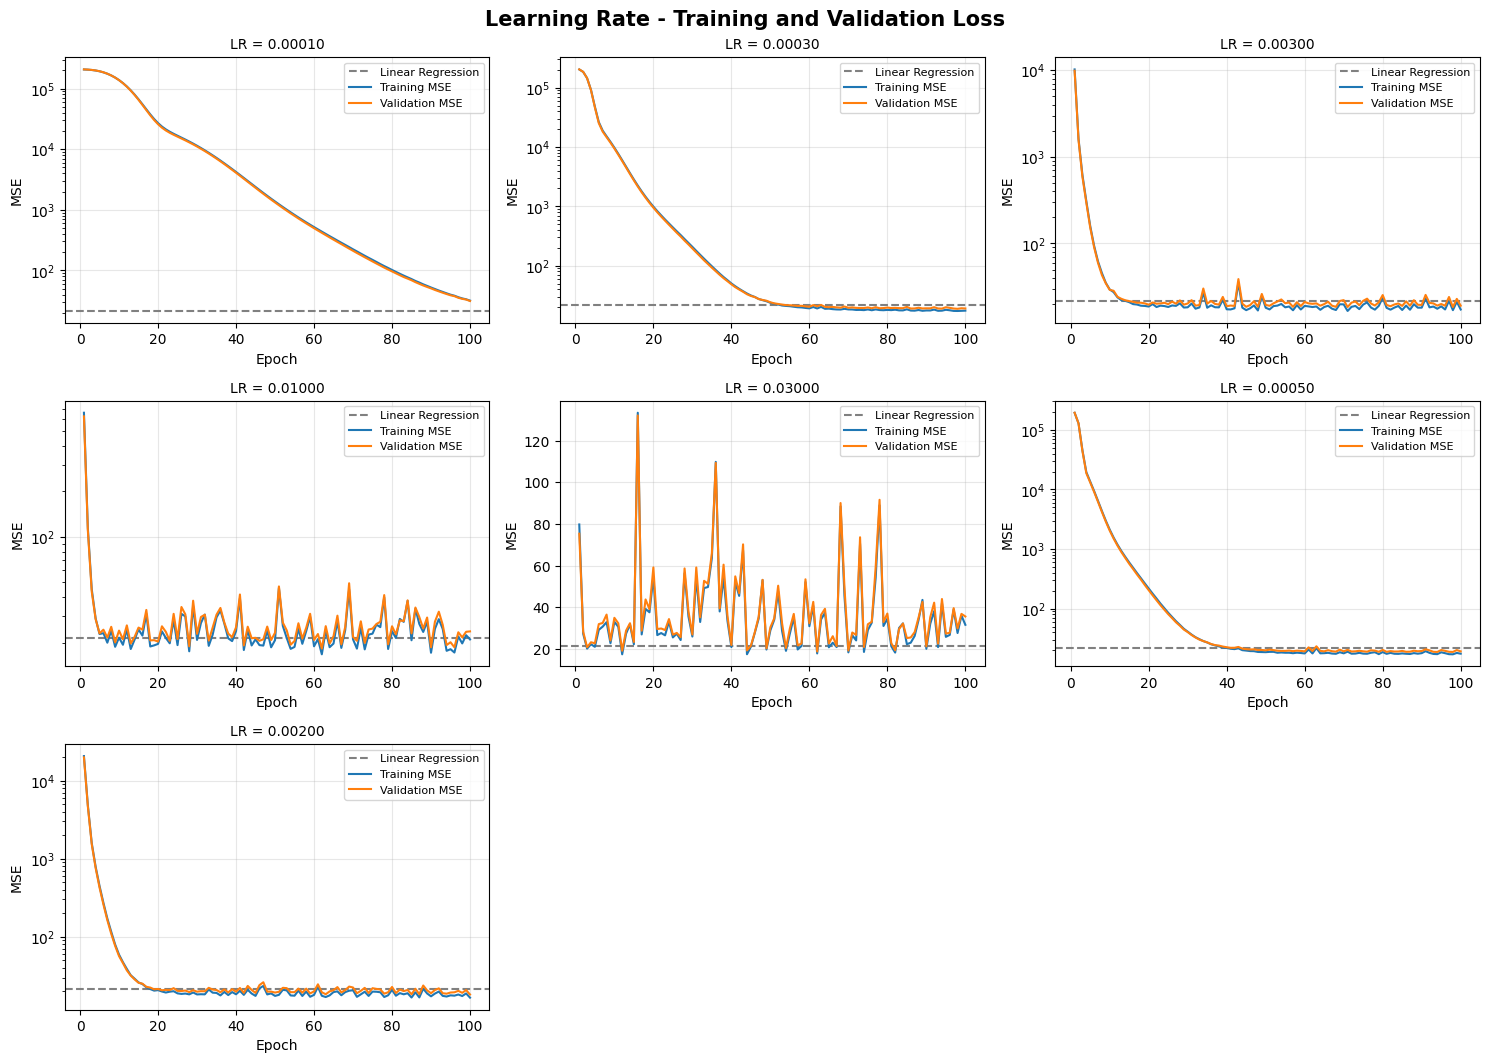

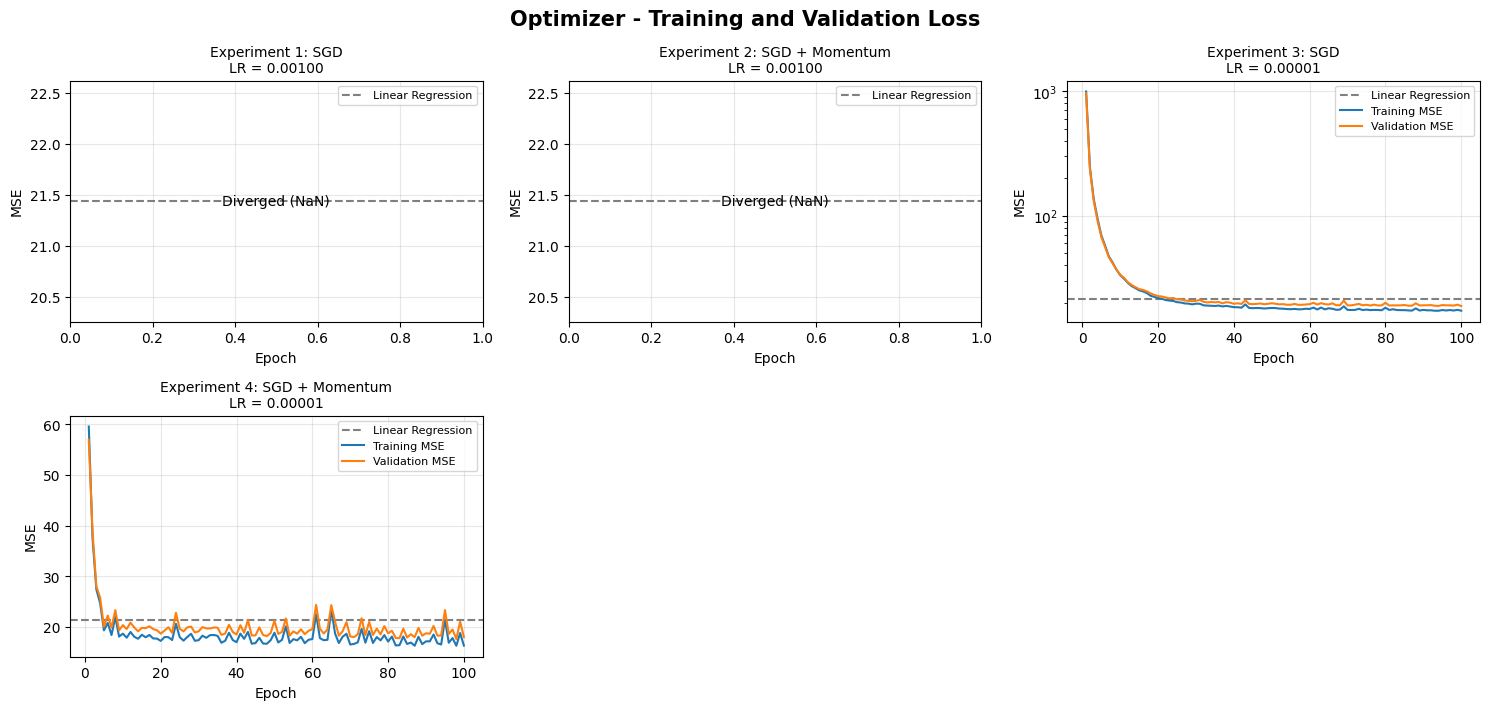

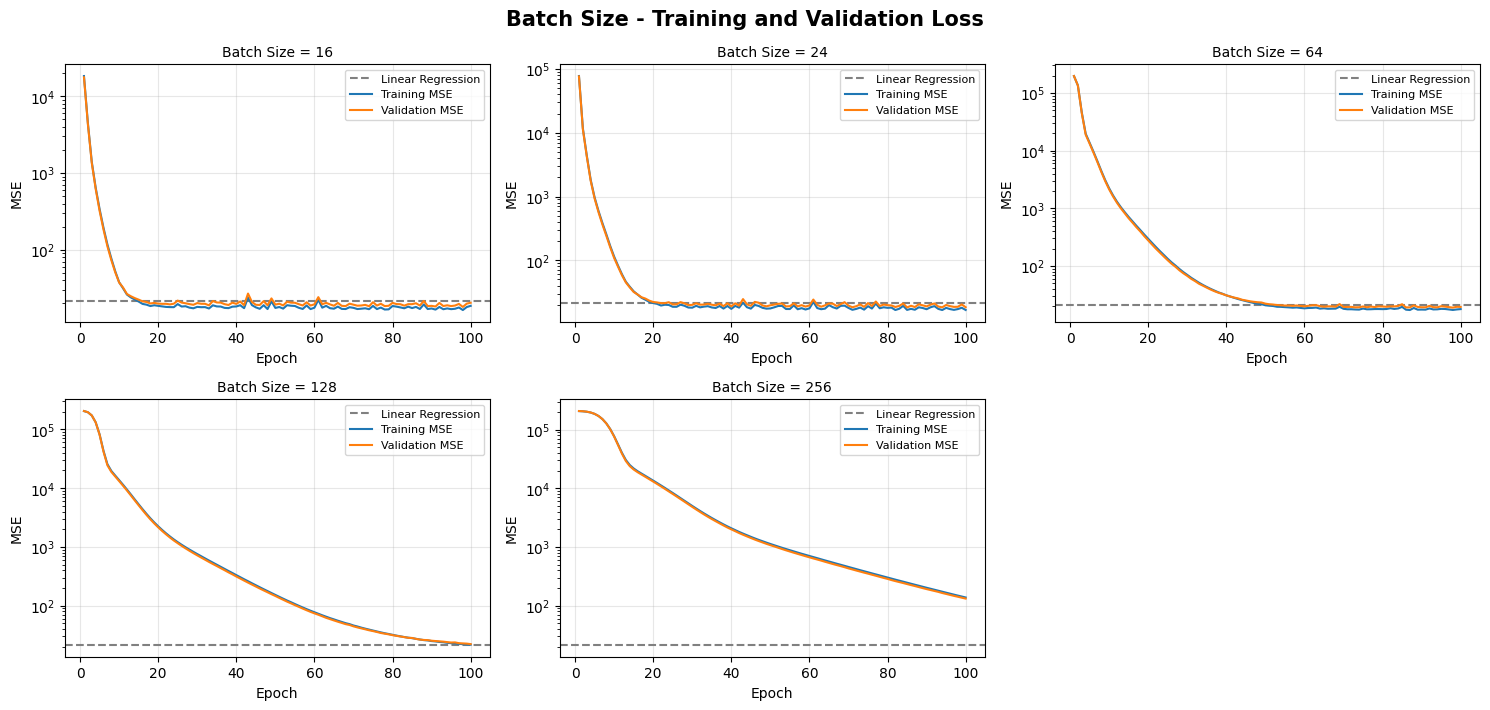

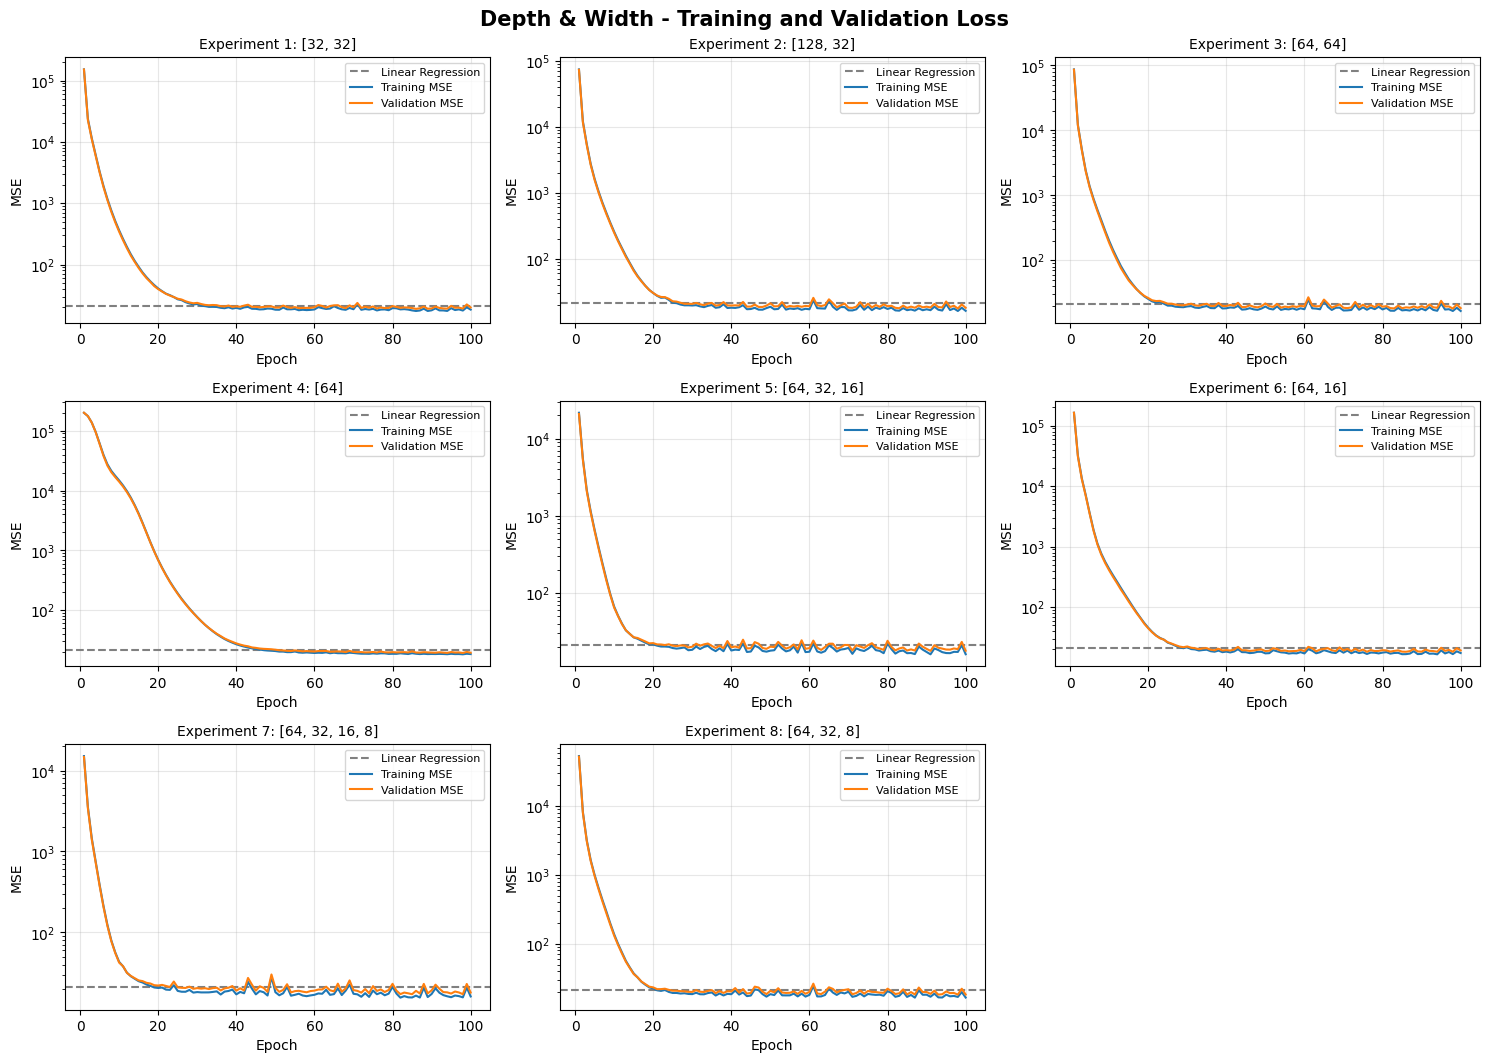

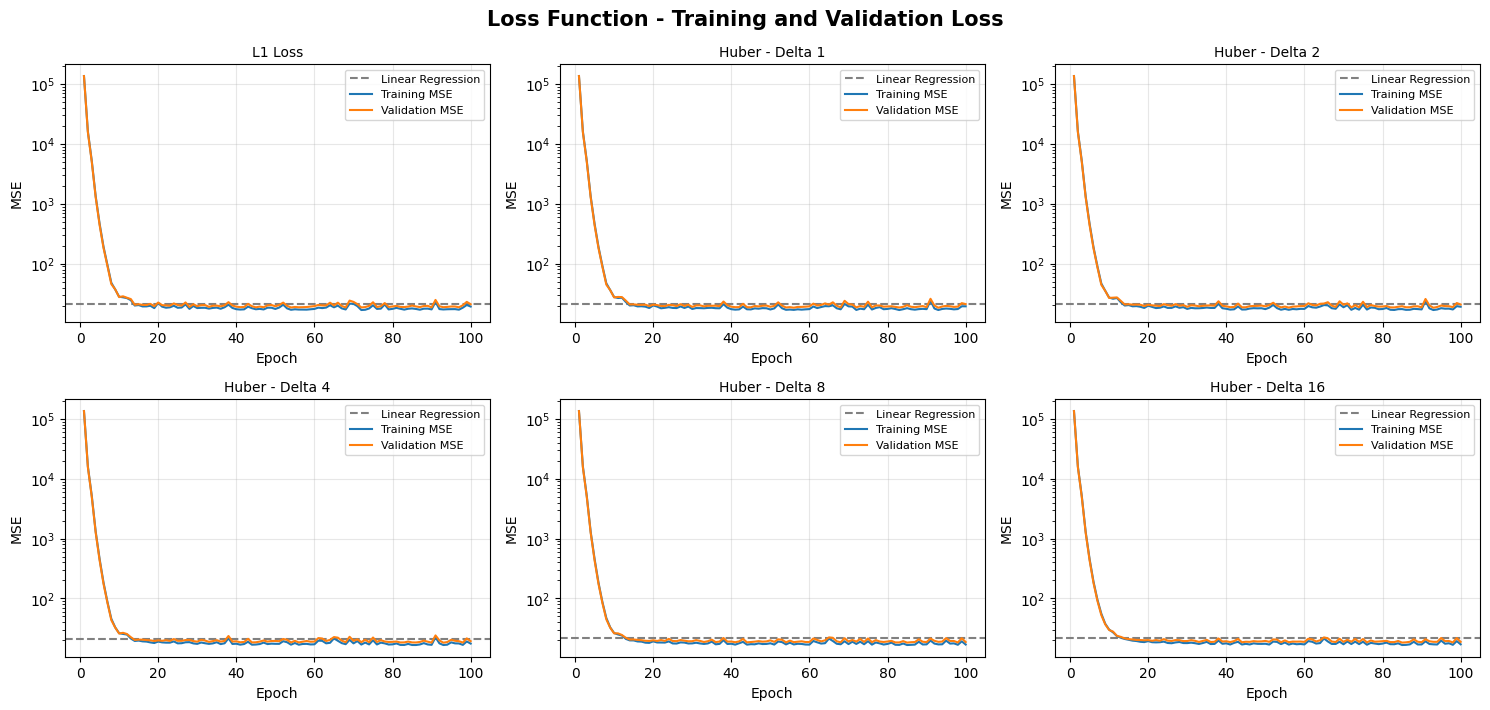

In [363]:

# Loss Curves & Results Analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

# Linear Regression reference
linear_val_mse = 21.4396

# Get loss histories from experiment results
def get_history(result, keys):
    for key in keys:
        if key in result and result[key] is not None:
            return np.asarray(result[key], dtype=float)
    return None


# Plot experiments by topic
def plot_topic_curves(topic, experiments):

    n = len(experiments)
    cols = 3
    rows = math.ceil(n / cols)

    fig, axes = plt.subplots(
        rows, cols,
        figsize=(15, 3.6 * rows),
        squeeze=False
    )

    for ax, (name, result) in zip(
        axes.flat, experiments
    ):

        train = get_history(
            result,
            ["Train Losses", "Train MSE History"]
        )

        val = get_history(
            result,
            ["Val Losses", "Val MSE History"]
        )

        ax.set_title(name, fontsize=10)

        ax.axhline(
            linear_val_mse,
            color="gray",
            linestyle="--",
            label="Linear Regression"
        )

        if train is None or val is None:
            ax.text(
                0.5, 0.5,
                "Loss history unavailable",
                ha="center", va="center",
                transform=ax.transAxes
            )

        elif not np.isfinite(train).any() or not np.isfinite(val).any():
            ax.text(
                0.5, 0.5,
                "Diverged (NaN)",
                ha="center", va="center",
                transform=ax.transAxes
            )

        else:
            ax.plot(
                range(1, len(train) + 1),
                train,
                label="Training MSE"
            )

            ax.plot(
                range(1, len(val) + 1),
                val,
                label="Validation MSE"
            )

            # Log scale if initial losses are very large
            finite = np.concatenate([
                train[np.isfinite(train)],
                val[np.isfinite(val)]
            ])

            positive = finite[finite > 0]

            if len(positive) > 0:
                if positive.max() / positive.min() > 20:
                    ax.set_yscale("log")

        ax.set_xlabel("Epoch")
        ax.set_ylabel("MSE")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)

    # Hide unused panels
    for ax in axes.flat[n:]:
        ax.axis("off")

    fig.suptitle(
        f"{topic} - Training and Validation Loss",
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()


# 1. Learning Rate
lr_experiments = [
    (f"LR = {r['Learning Rate']:.5f}", r)
    for r in lr_results
]

plot_topic_curves(
    "Learning Rate",
    lr_experiments
)


# 2. Optimizer
optimizer_experiments = [
    (
        f"Experiment {i}: {r['Optimizer']}\n"
        f"LR = {r['Learning Rate']:.5f}",
        r
    )
    for i, r in enumerate(optimizer_results, 1)
]

plot_topic_curves(
    "Optimizer",
    optimizer_experiments
)


# 3. Batch Size
batch_experiments = [
    (f"Batch Size = {r['Batch Size']}", r)
    for r in batch_results
]

plot_topic_curves(
    "Batch Size",
    batch_experiments
)


# 4. Depth & Width
architecture_experiments = sorted(
    architecture_results.items(),
    key=lambda item: int(item[0].split()[-1])
)

architecture_experiments = [
    (
        f"{name}: {r['Architecture']}",
        r
    )
    for name, r in architecture_experiments
]

plot_topic_curves(
    "Depth & Width",
    architecture_experiments
)


# 5. Loss Function
loss_experiments = [
    ("L1 Loss", l1_result),
    ("Huber - Delta 1", huber_1_result),
    ("Huber - Delta 2", huber_2_result),
    ("Huber - Delta 4", huber_4_result),
    ("Huber - Delta 8", huber_8_result),
    ("Huber - Delta 16", huber_16_result)
]

plot_topic_curves(
    "Loss Function",
    loss_experiments
)


# **Best Model Selection**


In [365]:

# Best Model Selection

import numpy as np

# Select valid experiments only
valid_results = all_results_table[
    (all_results_table["Topic"] != "Baseline") &
    np.isfinite(all_results_table["Val MSE"])
].copy()

# Select the model with the lowest Validation MSE
best_row = valid_results.loc[
    valid_results["Val MSE"].idxmin()
]

# Linear Regression reference
linear_val_mse = 21.4396

# Calculate improvement
improvement = (
    (linear_val_mse - best_row["Val MSE"])
    / linear_val_mse
) * 100

print("Best Model Selection")
print("----------------------------")
print("Topic:", best_row["Topic"])
print("Run:", best_row["Run"])
print("Configuration:", best_row["Configuration"])
print(f"Training MSE: {best_row['Train MSE']:.4f}")
print(f"Validation MSE: {best_row['Val MSE']:.4f}")
print(f"Linear Regression Val MSE: {linear_val_mse:.4f}")
print(f"Improvement: {improvement:.2f}%")


Best Model Selection
----------------------------
Topic: Depth & Width
Run: Experiment 5
Configuration: Architecture = [64, 32, 16]
Training MSE: 16.1674
Validation MSE: 17.9470
Linear Regression Val MSE: 21.4396
Improvement: 16.29%


# **Final Test Evaluation**

In [371]:

# Rebuild and Train the Selected Best Model

import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

generator = torch.Generator().manual_seed(42)

# Same training DataLoader
best_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    generator=generator
)

# Selected architecture: [64, 32, 16]
best_model = nn.Sequential(
    nn.Linear(4, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 16),
    nn.ReLU(),
    nn.Linear(16, 1)
).to(device)

# Same baseline settings
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    best_model.parameters(),
    lr=0.001
)

start_time = time.perf_counter()

# Training
for epoch in range(100):

    best_model.train()

    for xb, yb in best_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        predictions = best_model(xb)
        loss = criterion(predictions, yb)

        loss.backward()
        optimizer.step()

training_time = time.perf_counter() - start_time

# Check validation performance before testing
best_model.eval()

with torch.no_grad():
    best_val_mse = criterion(
        best_model(X_val_tensor.to(device)),
        y_val_tensor.to(device)
    ).item()

print("Selected Architecture: [64, 32, 16]")
print(f"Validation MSE: {best_val_mse:.4f}")
print(f"Training Time: {training_time:.2f} seconds")
print("Epochs Completed: 100")
print(f"Retrained Model Val MSE: {best_val_mse:.4f}")

Selected Architecture: [64, 32, 16]
Validation MSE: 17.9470
Training Time: 32.01 seconds
Epochs Completed: 100
Retrained Model Val MSE: 17.9470


In [372]:

# Final Test Evaluation - Run Once

import numpy as np
import torch
import torch.nn as nn

# Prepare test tensors
X_test_tensor = torch.tensor(
    np.asarray(X_test_scaled),
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    np.asarray(y_test).reshape(-1, 1),
    dtype=torch.float32
)

# Evaluation metric
criterion = nn.MSELoss()

# Evaluate the selected best model
best_model.eval()

with torch.no_grad():
    test_predictions = best_model(
        X_test_tensor.to(device)
    )

    test_mse = criterion(
        test_predictions,
        y_test_tensor.to(device)
    ).item()

# Display final results
print("Final Test Evaluation")
print("----------------------------")
print("Best Architecture: [64, 32, 16]")
print(f"Validation MSE: {best_val_mse:.4f}")
print(f"Test MSE: {test_mse:.4f}")
print(f"Test RMSE: {np.sqrt(test_mse):.4f}")


Final Test Evaluation
----------------------------
Best Architecture: [64, 32, 16]
Validation MSE: 17.9470
Test MSE: 18.5319
Test RMSE: 4.3049


In [373]:

# Final Model Comparison

import pandas as pd
import numpy as np

linear_val = 21.4396
baseline_val = nn_val_mse
best_val = best_val_mse

final_comparison = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "Val MSE": linear_val,
        "Test MSE": np.nan,
        "Improvement (%)": 0.0
    },
    {
        "Model": "Baseline Neural Network",
        "Val MSE": baseline_val,
        "Test MSE": np.nan,
        "Improvement (%)":
            (linear_val - baseline_val) / linear_val * 100
    },
    {
        "Model": "Best Neural Network [64, 32, 16]",
        "Val MSE": best_val,
        "Test MSE": test_mse,
        "Improvement (%)":
            (linear_val - best_val) / linear_val * 100
    }
])

display(
    final_comparison.style.format({
        "Val MSE": "{:.4f}",
        "Test MSE": "{:.4f}",
        "Improvement (%)": "{:.2f}%"
    }, na_rep="—")
)


,Model,Val MSE,Test MSE,Improvement (%)
0,Linear Regression,21.4396,—,0.00%
1,Baseline Neural Network,18.6084,—,13.21%
2,"Best Neural Network [64, 32, 16]",17.9470,18.5319,16.29%
